# Phase 2 : Data Acquisition

In this phase, we prepare and process the CT scan data for training a deep learning model to detect lung nodules.

## 1. Check and Understand CT Scan Structure

We examined the structure of the CT scan data, focusing on loading `.mhd` files, extracting the shape (dimensions) and voxel spacing of each scan, and analyzing their distribution.

### What We Did:
- We **loaded** the `.mhd` files using `SimpleITK`
- We **retrieved** the scan dimensions and voxel spacing
- We **analyzed** whether the scans had consistent properties

### Why This Matters:
Before performing any preprocessing or model training, it's crucial to understand:
- What are the typical shapes (dimensions) of the CT scans?
- What is the voxel spacing in millimeters?
- Do we need to normalize dimensions or resample spacing?

### Tools Used:
- `SimpleITK` to read `.mhd` files
- `os` and `glob` to iterate through scan files
- `numpy` for basic statistical analysis

In [4]:
import SimpleITK as sitk
import os
import numpy as np
import glob
import matplotlib.pyplot as plt
import random
import gc
import scipy.ndimage
from tqdm import tqdm
from multiprocessing import Pool, cpu_count


In [2]:
data_path = "/../media/farah/ADATA SD620/luna 16/final/dataset"
normalized_dir = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
mask_dir = "/media/farah/ADATA SD620/luna 16/final/seg-lungs-LUNA16"
output_dir = "/media/farah/ADATA SD620/luna 16/final/segmented_images"

In [3]:
mhd_files = glob.glob(os.path.join(data_path, "*.mhd"))

In [6]:
mhd_files = glob.glob(os.path.join(data_path, "*.mhd"))

image_sizes = []
image_spacings = []

for file in mhd_files:
    img = sitk.ReadImage(file)
    size = img.GetSize()         # (x, y, z)
    spacing = img.GetSpacing()   # (spacing_x, spacing_y, spacing_z)

    image_sizes.append(size)
    image_spacings.append(spacing)

image_sizes = np.array(image_sizes)
image_spacings = np.array(image_spacings)

📐 Size stats (voxels):
Min: [512 512 103]
Max: [512 512 764]
Mean: [512.         512.         253.40175219]
Std Dev: [  0.           0.         133.32335295]

📏 Spacing stats (mm):
Min: [0.4609375  0.4609375  0.45000002]
Max: [0.97656202 0.97656202 2.50000024]
Mean: [0.69120796 0.69120796 1.58541927]
Std Dev: [0.08443696 0.08443696 0.72351776]


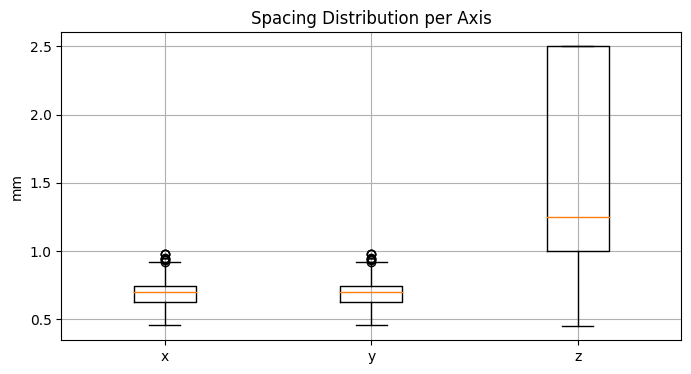

In [7]:
print("📐 Size stats (voxels):")
print("Min:", np.min(image_sizes, axis=0))
print("Max:", np.max(image_sizes, axis=0))
print("Mean:", np.mean(image_sizes, axis=0))
print("Std Dev:", np.std(image_sizes, axis=0))

print("\n📏 Spacing stats (mm):")
print("Min:", np.min(image_spacings, axis=0))
print("Max:", np.max(image_spacings, axis=0))
print("Mean:", np.mean(image_spacings, axis=0))
print("Std Dev:", np.std(image_spacings, axis=0))

# Optional: Visualize spacing variation
plt.figure(figsize=(8, 4))
plt.title("Spacing Distribution per Axis")
plt.boxplot(image_spacings, labels=["x", "y", "z"])
plt.ylabel("mm")
plt.grid(True)
plt.show()


### Interpretation of Our CT Scan Statistics

#### Voxel Dimensions (Image Shape)
- **X and Y dimensions:** Always `[512, 512]` → Consistent across all scans  
- **Z dimension (depth):** Varies significantly — ranges from **109 to 733 slices**  
  ➤ This is expected due to differences in patient scan lengths.

 **Implication:**  
We **cannot** feed entire scans directly into a model because of this depth variation.  
We will either:
- Extract uniform-sized 3D patches, **or**
- Resample scans to a consistent shape and spacing.

---

#### Voxel Spacing (Physical Size in mm)
- **X and Y spacing:**  
  Ranges from **~0.51 mm to 0.97 mm** → Minor variation, generally manageable 

- **Z spacing (slice thickness):**  
  Ranges from **0.5 mm to 2.5 mm**  → Significant variation

→ This means that even if two scans have the same number of slices, they can represent very different physical depths.

---

#### Solution:
To ensure spatial consistency across all scans, we will:
- **Normalize Hounsfield Unit (HU) values** in the next step (Step 2)
- **Resample all volumes** to a uniform voxel spacing (e.g., **1.0 mm × 1.0 mm × 1.0 mm**) later (Step 4)

---

#### Summary:
| Property                | Status     | Notes                                      |
|------------------------|------------|--------------------------------------------|
| X/Y Shape              | Consistent | Always 512 × 512                          |
| Z Shape (Slices)       | Variable  | 109 to 733 slices                          |
| X/Y Spacing (mm)       | Slight variation | ~0.51–0.97 mm                     |
| Z Spacing (mm)         | Highly variable | 0.5–2.5 mm                          |

These observations guide our next preprocessing steps to standardize scan inputs for modeling.


## 2. Resample Scans and Masks to 1mm³ Voxel Spacing

CT scans in the LUNA16 dataset vary significantly in voxel spacing, especially along the **z-axis (slice thickness)** — ranging from **0.5 mm to 2.5 mm**. This variation makes it challenging to apply 3D convolutional neural networks directly, as different scans represent different physical volumes even if they have the same number of slices.

###  Objective:
We resample both the CT scans and their corresponding **lung masks** to a **uniform voxel spacing of 1.0 mm × 1.0 mm × 1.0 mm**. This ensures spatial consistency across all patients and enables meaningful learning in 3D space.

###  Method:
- We used **SimpleITK** to load `.mhd` images and apply resampling using `sitk.ResampleImageFilter`.
- **Linear interpolation** was used for CT scans to preserve intensity gradients.
- **Nearest-neighbor interpolation** was used for lung masks to preserve discrete label boundaries.
- **Multiprocessing** was applied for speed, resampling all scans in parallel.

###  Output:
- Resampled CT scans and masks were saved as compressed `.npz` files (NumPy format).
- Each `.npz` file contains a 3D array in `(z, y, x)` order.

In [3]:
import os
import numpy as np
import SimpleITK as sitk
from tqdm import tqdm
from multiprocessing import Pool

# 📂 Paths
input_scans_folder = "/media/farah/ADATA SD620/luna 16/final/dataset"  # Your original CT scans (.mhd)
input_masks_folder = "/media/farah/ADATA SD620/luna 16/final/seg-lungs-LUNA16"  # Your original lung masks (.mhd)

output_scans_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_scans"
output_masks_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_masks"

os.makedirs(output_scans_folder, exist_ok=True)
os.makedirs(output_masks_folder, exist_ok=True)

# ⚙️ Settings
new_spacing = [1.0, 1.0, 1.0]  # 1mm x 1mm x 1mm

# 📌 Helper function to resample
def resample_image(image, new_spacing=[1.0, 1.0, 1.0], is_label=False):
    original_spacing = image.GetSpacing()
    original_size = image.GetSize()

    new_size = [
        int(round(original_size[0] * (original_spacing[0] / new_spacing[0]))),
        int(round(original_size[1] * (original_spacing[1] / new_spacing[1]))),
        int(round(original_size[2] * (original_spacing[2] / new_spacing[2])))
    ]

    resample = sitk.ResampleImageFilter()
    resample.SetOutputSpacing(new_spacing)
    resample.SetSize(new_size)
    resample.SetOutputDirection(image.GetDirection())
    resample.SetOutputOrigin(image.GetOrigin())
    resample.SetTransform(sitk.Transform())
    resample.SetDefaultPixelValue(-1024 if not is_label else 0)

    if is_label:
        resample.SetInterpolator(sitk.sitkNearestNeighbor)
    else:
        resample.SetInterpolator(sitk.sitkLinear)

    return resample.Execute(image)

# 🚀 Processing function for one scan
def process_one_scan(filename):
    try:
        if not filename.endswith(".mhd"):
            return
        
        seriesuid = filename.replace('.mhd', '')

        # Load scan and mask
        scan_path = os.path.join(input_scans_folder, filename)
        mask_path = os.path.join(input_masks_folder, f"{seriesuid}.mhd")

        scan = sitk.ReadImage(scan_path)
        mask = sitk.ReadImage(mask_path)

        # Resample
        scan_resampled = resample_image(scan, new_spacing, is_label=False)
        mask_resampled = resample_image(mask, new_spacing, is_label=True)

        # Convert to numpy
        scan_np = sitk.GetArrayFromImage(scan_resampled)  # (z,y,x)
        mask_np = sitk.GetArrayFromImage(mask_resampled)  # (z,y,x)

        # Save compressed
        np.savez_compressed(os.path.join(output_scans_folder, f"{seriesuid}.npz"), scan=scan_np)
        np.savez_compressed(os.path.join(output_masks_folder, f"{seriesuid}_lungmask.npz"), mask=mask_np)

        return f"✅ {seriesuid} done."

    except Exception as e:
        return f"⚠️ Error processing {filename}: {e}"

# 🚀 Run multiprocessing
if __name__ == "__main__":
    filenames = os.listdir(input_scans_folder)
    num_workers = 8

    print(f"🚀 Starting resampling with {num_workers} workers...")

    with Pool(num_workers) as pool:
        for result in tqdm(pool.imap_unordered(process_one_scan, filenames), total=len(filenames)):
            if result:
                print(result)

    print("✅ All scans and masks resampled and saved!")


🚀 Starting resampling with 8 workers...


  1%|▏                                         | 9/1776 [00:10<33:51,  1.15s/it]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793540579077826395208 done.


  1%|▏                                        | 10/1776 [00:10<30:26,  1.03s/it]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.123654356399290048011621921476 done.


...

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.943403138251347598519939390311 done.


100%|██████████████████████████████████████▉| 1775/1776 [33:00<00:01,  1.17s/it]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.948414623428298219623354433437 done.
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.944888107209008719031293531091 done.


100%|███████████████████████████████████████| 1776/1776 [33:01<00:00,  1.12s/it]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.939216568327879462530496768794 done.
✅ All scans and masks resampled and saved!


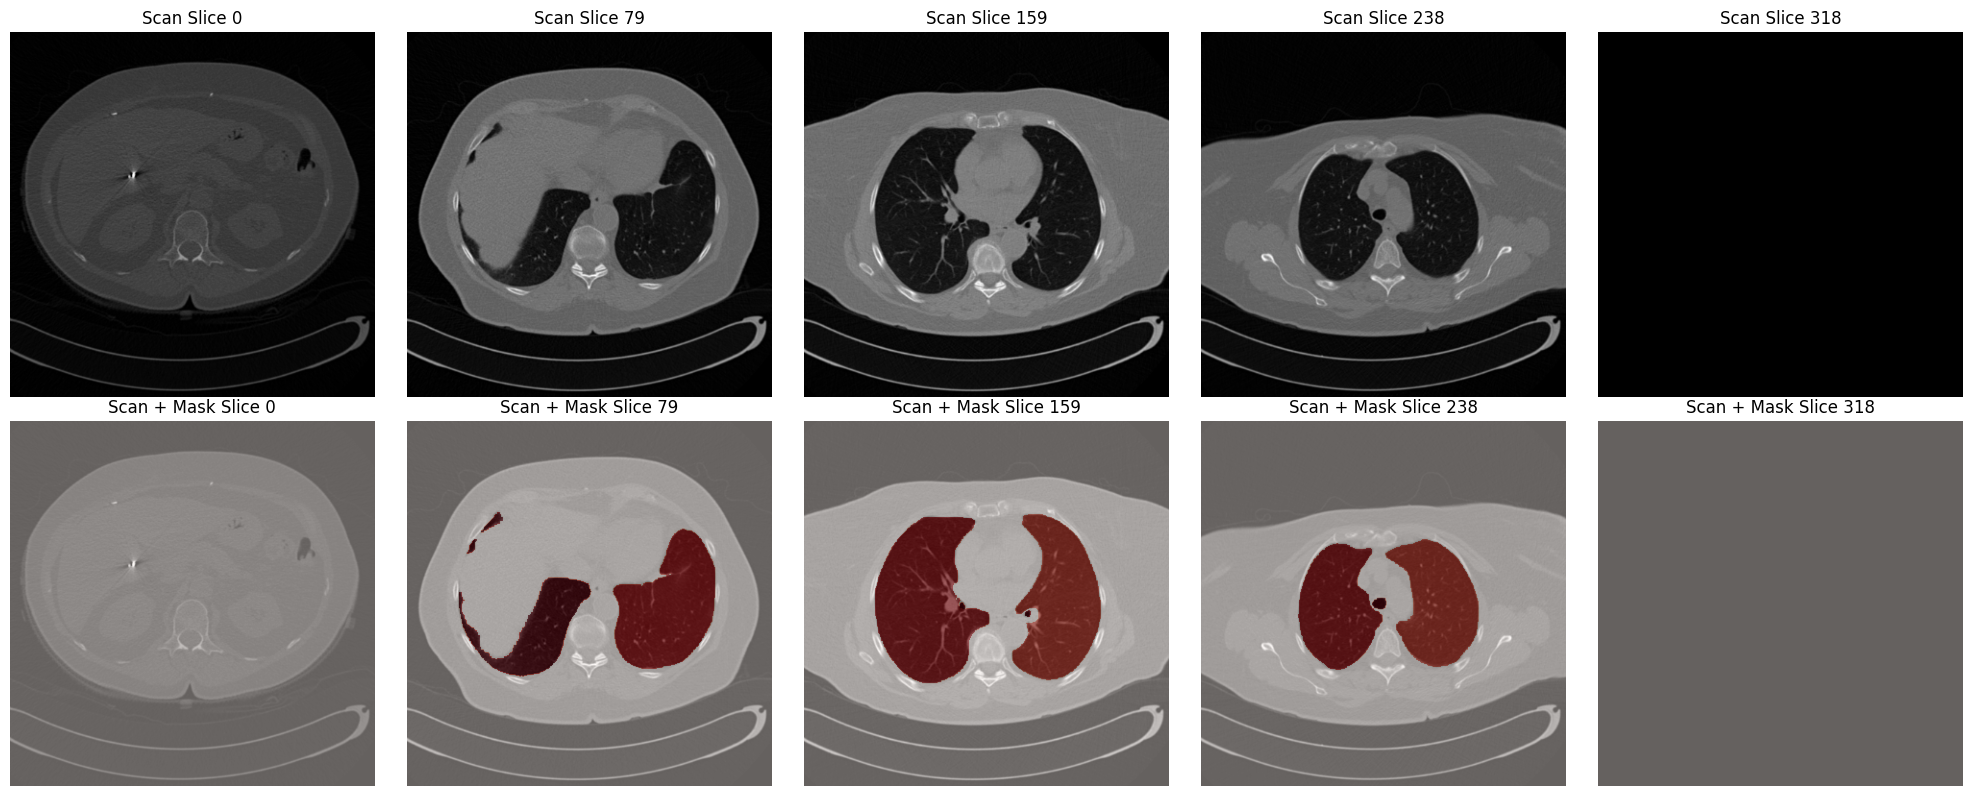

✅ Visualized 1.3.6.1.4.1.14519.5.2.1.6279.6001.277445975068759205899107114231


In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt

# 📂 Paths
scan_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_scans"
mask_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_masks"

# 📋 Pick one file
example_seriesuid = random.choice([
    f.replace('.npz', '') for f in os.listdir(scan_folder) if f.endswith('.npz')
])

# 📂 Load
scan_data = np.load(os.path.join(scan_folder, f"{example_seriesuid}.npz"))['scan']
mask_data = np.load(os.path.join(mask_folder, f"{example_seriesuid}_lungmask.npz"))['mask']

# 🖼 Plot
num_slices = 5
z_indices = np.linspace(0, scan_data.shape[0]-1, num_slices, dtype=int)

fig, axes = plt.subplots(2, num_slices, figsize=(20, 8))

for i, z in enumerate(z_indices):
    axes[0, i].imshow(scan_data[z], cmap='gray')
    axes[0, i].set_title(f"Scan Slice {z}")
    axes[0, i].axis('off')

    # Overlay mask in red
    axes[1, i].imshow(scan_data[z], cmap='gray')
    axes[1, i].imshow(mask_data[z], cmap='Reds', alpha=0.4)
    axes[1, i].set_title(f"Scan + Mask Slice {z}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

print(f"✅ Visualized {example_seriesuid}")


###  Visualization Example:
Above is a sample output showing:
- Top row: CT scan slices at various depths
- Bottom row: The same slices overlaid with the resampled lung mask in red

This confirms the masks align correctly with lung regions after resampling.

**Conclusion:** Resampling is complete, and all data is now spatially aligned at 1 mm³ resolution — ready for consistent patch extraction and model input.


## 3. Apply Lung Mask (Extract Lung-Only Regions)

###  Goal:
To focus our analysis on the **lungs only**, we applied lung segmentation masks to each resampled CT scan. This removes irrelevant structures such as the chest wall, bones, and background — which simplifies the learning task and reduces noise for downstream models.

###  What We Did:
- Loaded each **resampled CT scan** and its corresponding **resampled lung mask**.
- Applied the mask using:  
  `masked_scan = scan * (mask > 0)`  
  This keeps only the lung regions and sets everything else to zero.
- Used **multiprocessing (8 workers)** to accelerate the operation across the entire dataset.
- Saved the resulting **lung-masked scans** as compressed `.npz` files.

###  Output Folder:
`/media/farah/ADATA SD620/luna 16/final/lung_masked_scans`



In [7]:
import os
import numpy as np
from tqdm import tqdm
from multiprocessing import Pool

# 📂 Paths
resampled_scans_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_scans"
resampled_masks_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_masks"
output_folder = "/media/farah/ADATA SD620/luna 16/final/lung_masked_scans"  # 🔥 New folder only with mask applied
os.makedirs(output_folder, exist_ok=True)

# 📋 List all scan files
scan_files = [f for f in os.listdir(resampled_scans_folder) if f.endswith('.npz')]

# 📌 Function to apply lung mask only
def apply_lung_mask(filename):
    try:
        scan_path = os.path.join(resampled_scans_folder, filename)
        mask_path = os.path.join(resampled_masks_folder, filename.replace('.npz', '_lungmask.npz'))

        # Load scan and mask
        scan_data = np.load(scan_path)['scan']
        mask_data = np.load(mask_path)['mask']

        # Apply lung mask
        scan_data = scan_data * (mask_data > 0)

        # Save
        out_path = os.path.join(output_folder, filename)
        np.savez_compressed(out_path, scan=scan_data)

        return f"✅ {filename} masked (lung only)."

    except Exception as e:
        return f"⚠️ Error with {filename}: {e}"

# 🚀 Run multiprocessing
if __name__ == "__main__":
    num_workers = 8
    print(f"🚀 Starting lung masking with {num_workers} workers...")

    with Pool(num_workers) as pool:
        for result in tqdm(pool.imap_unordered(apply_lung_mask, scan_files), total=len(scan_files)):
            if result:
                print(result)

    print("✅ All scans masked (lung only) and saved!")


🚀 Starting lung masking with 8 workers...


  0%|                                           | 2/888 [00:02<14:29,  1.02it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016233746780170740405.npz masked (lung only).
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163890911914061745866.npz masked (lung only).


  0%|▏                                          | 3/888 [00:02<08:55,  1.65it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793540579077826395208.npz masked (lung only).


...

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.690929968028676628605553365896.npz masked (lung only).
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.692598144815688523679745963696.npz masked (lung only).


100%|████████████████████████████████████████▉| 886/888 [07:11<00:00,  4.96it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.710845873679853791427022019413.npz masked (lung only).


100%|█████████████████████████████████████████| 888/888 [07:12<00:00,  2.05it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.712472578497712558367294720243.npz masked (lung only).
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.716498695101447665580610403574.npz masked (lung only).
✅ All scans masked (lung only) and saved!


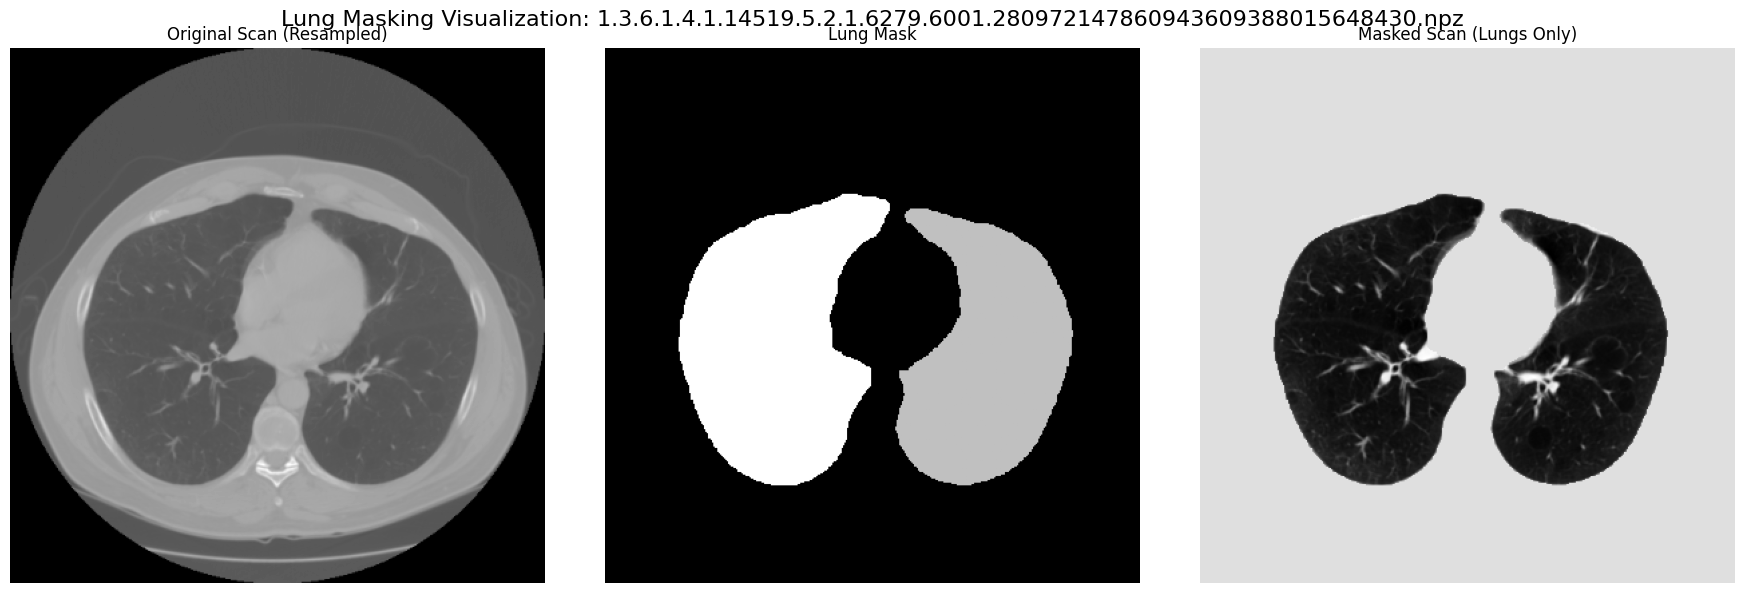

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import random

# 📂 Paths
masked_scans_folder = "/media/farah/ADATA SD620/luna 16/final/lung_masked_scans"
resampled_scans_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_scans"
resampled_masks_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_masks"

# 📋 Pick a random scan
masked_files = [f for f in os.listdir(masked_scans_folder) if f.endswith('.npz')]
sample_file = random.choice(masked_files)

# 📥 Load scan and mask
masked_scan = np.load(os.path.join(masked_scans_folder, sample_file))['scan']
original_scan = np.load(os.path.join(resampled_scans_folder, sample_file))['scan']
mask = np.load(os.path.join(resampled_masks_folder, sample_file.replace('.npz', '_lungmask.npz')))['mask']

# 🎯 Pick the middle slice
mid_slice = original_scan.shape[0] // 2

# 🎨 Plot before/after
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(original_scan[mid_slice], cmap='gray')
axes[0].set_title('Original Scan (Resampled)')

axes[1].imshow(mask[mid_slice], cmap='gray')
axes[1].set_title('Lung Mask')

axes[2].imshow(masked_scan[mid_slice], cmap='gray')
axes[2].set_title('Masked Scan (Lungs Only)')

for ax in axes:
    ax.axis('off')

plt.suptitle(f"Lung Masking Visualization: {sample_file}", fontsize=16)
plt.tight_layout()
plt.show()


###  Visualization Example:
Above is a visualization of the masking process on one resampled scan:

- **Left**: Original resampled scan  
- **Middle**: Lung mask  
- **Right**: Masked scan (lungs only)


**Conclusion:** We now have lung-only scans, which will serve as the clean input for further preprocessing and patch extraction.


## 4. Clip Hounsfield Units & Normalize to [0, 1]

### Goal:
To prepare voxel intensity values for input into deep learning models like **3D U-Net**, we perform two main steps:

---

### Clipping:
We clip the raw CT values to the range **[-1000, 400] Hounsfield Units (HU)**:
- **Why?** This retains only the intensities relevant to lung tissue (air to soft tissue).
- It removes outliers such as bones, noise, or metallic implants.

---

### Normalization:
After clipping, we normalize all voxel values to the range **[0, 1]**:
- `-1000 HU` → `0.0`
- `400 HU` → `1.0`
- Values in between are linearly scaled.

---




In [11]:
import os
import numpy as np
from tqdm import tqdm
from multiprocessing import Pool

# 📂 Folder paths
resampled_scans_folder = "/media/farah/ADATA SD620/luna 16/final/lung_masked_scans"
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
os.makedirs(normalized_scans_folder, exist_ok=True)

# 📋 List all files
scan_files = [f for f in os.listdir(resampled_scans_folder) if f.endswith('.npz')]

# 📌 Normalization function
def normalize_one_scan(filename):
    try:
        scan_path = os.path.join(resampled_scans_folder, filename)
        data = np.load(scan_path)
        scan = data['scan']  # (z,y,x)

        # ✨ Clip and normalize
        scan = np.clip(scan, -1000, 400)
        scan = (scan + 1000) / 1400

        # Save normalized
        out_path = os.path.join(normalized_scans_folder, filename)
        np.savez_compressed(out_path, scan=scan)

        return f"✅ {filename} normalized."

    except Exception as e:
        return f"⚠️ Error with {filename}: {e}"

# 🚀 Run multiprocessing
if __name__ == "__main__":
    num_workers = 8
    print(f"🚀 Starting normalization with {num_workers} workers...")

    with Pool(num_workers) as pool:
        for result in tqdm(pool.imap_unordered(normalize_one_scan, scan_files), total=len(scan_files)):
            if result:
                print(result)

    print("✅ All scans normalized and saved!")


🚀 Starting normalization with 8 workers...


  0%|                                           | 1/888 [00:03<45:28,  3.08s/it]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016233746780170740405.npz normalized.


  0%|                                           | 2/888 [00:03<20:58,  1.42s/it]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163890911914061745866.npz normalized.
✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793540579077826395208.npz normalized.


...

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.749871569713868632259874663577.npz normalized.


100%|████████████████████████████████████████▉| 887/888 [09:31<00:00,  2.16it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.747803439040091794717626507402.npz normalized.


100%|█████████████████████████████████████████| 888/888 [09:31<00:00,  1.55it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.745109871503276594185453478952.npz normalized.
✅ All scans normalized and saved!


📄 Visualizing: 1.3.6.1.4.1.14519.5.2.1.6279.6001.144943344795414353192059796098.npz
Shape: (281, 326, 326)
Min: 0.000, Max: 1.000


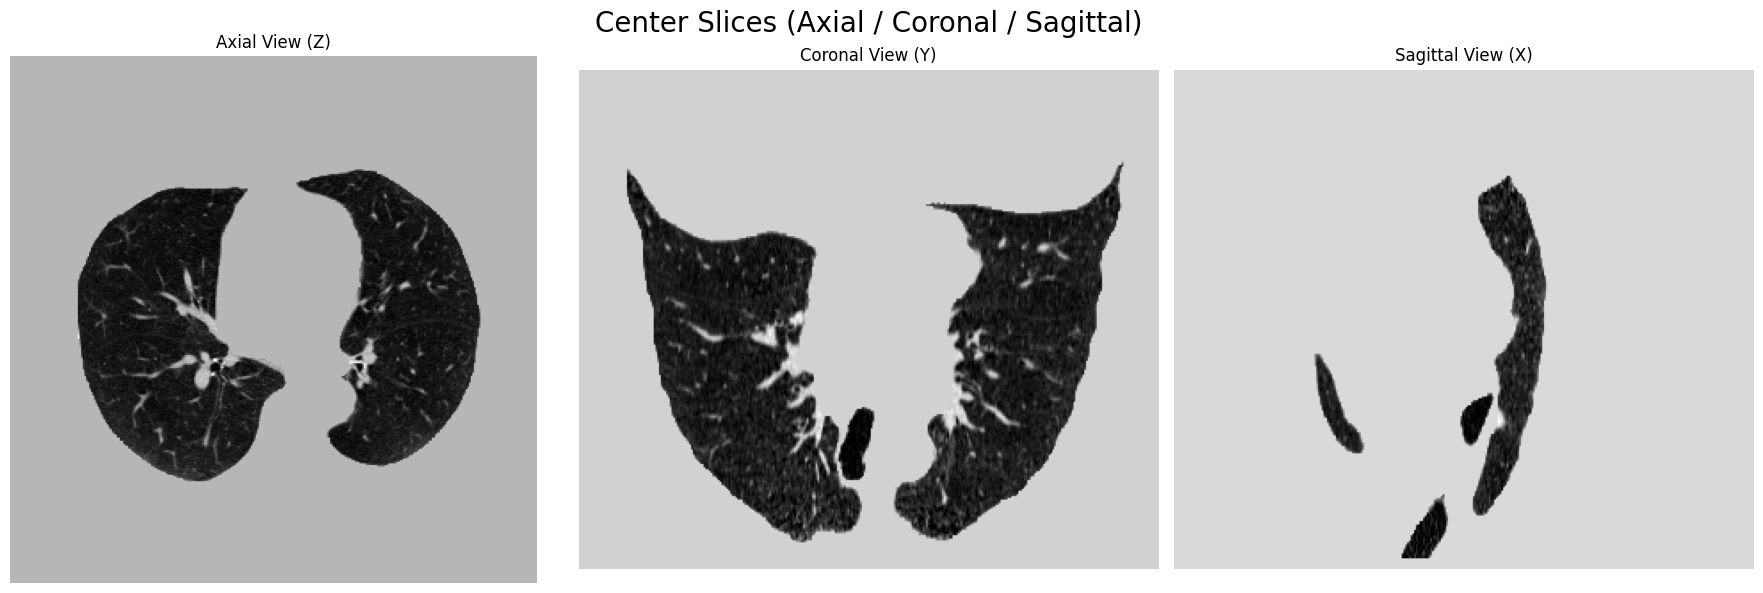

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
import random

# 📂 Normalized scans folder
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"

# 📋 List all normalized files
scan_files = [f for f in os.listdir(normalized_scans_folder) if f.endswith('.npz')]

# 🎯 Pick a random scan to visualize
random_scan = random.choice(scan_files)
scan_path = os.path.join(normalized_scans_folder, random_scan)

# 📖 Load scan
data = np.load(scan_path)
scan = data['scan']

print(f"📄 Visualizing: {random_scan}")
print(f"Shape: {scan.shape}")
print(f"Min: {scan.min():.3f}, Max: {scan.max():.3f}")

# 🎨 Plot center slices
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Center Slices (Axial / Coronal / Sagittal)', fontsize=20)

z, y, x = scan.shape
axes[0].imshow(scan[z//2, :, :], cmap='gray')
axes[0].set_title('Axial View (Z)')

axes[1].imshow(scan[:, y//2, :], cmap='gray')
axes[1].set_title('Coronal View (Y)')

axes[2].imshow(scan[:, :, x//2], cmap='gray')
axes[2].set_title('Sagittal View (X)')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


### Visualization:
Above we show the **center slices** from each axis (Axial, Coronal, Sagittal) of a normalized 3D lung-masked scan.

- **Left:** Axial view (Z)
- **Middle:** Coronal view (Y)
- **Right:** Sagittal view (X)

---

### Result:
All scans are now intensity-normalized and ready for input into neural networks. This improves convergence speed and model stability during training.



## 5. Match CT Scans with Nodule Annotations

### Goal:
To associate each preprocessed CT scan with its corresponding **lung nodule annotations**, and convert the annotation coordinates from **world space (mm)** to **voxel space** for training tumor detection models.

---

### What We Did:

-  **Loaded** the original `.mhd` scans to extract and save their **origin** (spatial reference point).
-  **Filtered** the nodule annotations to include only those for scans that were successfully normalized.
-  **Converted** the nodule center coordinates from **world coordinates (mm)** to **voxel coordinates (z, y, x)**:
  - This uses the formula:  
    \[
    \text{voxel} = \frac{\text{world} - \text{origin}}{\text{spacing}}
    \]
  - Spacing is fixed at **1mm × 1mm × 1mm** (due to prior resampling).
-  **Dropped** annotations without matching origins or scans.
-  **Saved** the resulting annotations to a new CSV file.

---

### Output:
Filtered annotations saved to:  
`/media/farah/ADATA SD620/luna 16/final/filtered_annotations.csv`

---


In [39]:
# ✅ Save Origin for Existing Scans Only

import os
import SimpleITK as sitk
import numpy as np
from tqdm import tqdm

# 📂 Paths
input_mhd_folder = "/media/farah/ADATA SD620/luna 16/final/dataset"  # Where your original .mhd files are
resampled_folder = "/media/farah/ADATA SD620/luna 16/final/resampled_scans"  # Already done resampling
origins_folder = "/media/farah/ADATA SD620/luna 16/final/origins"  # Where to save origins
os.makedirs(origins_folder, exist_ok=True)

# 📋 Get list of resampled scans
resampled_files = [f.replace('.npz', '') for f in os.listdir(resampled_folder) if f.endswith('.npz')]

# 🚀 Loop and save origins
for seriesuid in tqdm(resampled_files, desc="Saving Origins"):
    mhd_path = os.path.join(input_mhd_folder, f"{seriesuid}.mhd")
    output_origin_path = os.path.join(origins_folder, f"{seriesuid}_origin.npy")
    
    if not os.path.exists(mhd_path):
        print(f"⚠️ Missing original scan: {seriesuid}")
        continue

    if os.path.exists(output_origin_path):
        continue  # Skip if already saved

    scan = sitk.ReadImage(mhd_path)
    origin = np.array(scan.GetOrigin(), dtype=np.float32)
    np.save(output_origin_path, origin)

print("✅ All origins saved successfully!")


Saving Origins: 100%|█████████████████████████| 888/888 [07:01<00:00,  2.11it/s]

✅ All origins saved successfully!


In [69]:
import pandas as pd
import os
import numpy as np

# 📂 Paths
annotations_path = "/media/farah/ADATA SD620/luna 16/annotations.csv"
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
origins_folder = "/media/farah/ADATA SD620/luna 16/final/origins"

# 📚 Load annotations
df_annots = pd.read_csv(annotations_path)
print(f"✅ Loaded {len(df_annots)} annotations.")

# 📋 List all normalized scan filenames
scan_files = [f.replace('.npz', '') for f in os.listdir(normalized_scans_folder) if f.endswith('.npz')]
print(f"✅ Found {len(scan_files)} preprocessed (normalized) scans.")

# 🔎 Filter annotations to existing scans
filtered_annots = df_annots[df_annots['seriesuid'].isin(scan_files)]
print(f"✅ {len(filtered_annots)} annotations match available normalized scans.")

# ✏️ Rename columns
filtered_annots = filtered_annots.rename(columns={
    'coordX': 'coordX_world',
    'coordY': 'coordY_world',
    'coordZ': 'coordZ_world',
    'diameter_mm': 'diameter_mm'
})

# 📌 Define spacing (already 1mm x 1mm x 1mm)
spacing = np.array([1.0, 1.0, 1.0])

# 📌 World → Voxel conversion function
def world_to_voxel(world_coord, origin, spacing):
    return np.round((world_coord - origin) / spacing).astype(int)

# 📈 Compute voxel coordinates (corrected version)
coordZ_voxel = []
coordY_voxel = []
coordX_voxel = []

for idx, row in filtered_annots.iterrows():
    seriesuid = row['seriesuid']
    origin_path = os.path.join(origins_folder, f"{seriesuid}_origin.npy")
    
    if not os.path.exists(origin_path):
        # If missing origin, skip
        coordZ_voxel.append(np.nan)
        coordY_voxel.append(np.nan)
        coordX_voxel.append(np.nan)
        continue

    origin = np.load(origin_path)  # (x, y, z) from SimpleITK
    origin = origin[[2, 1, 0]]      # 🛠 Reorder to (z, y, x) for numpy

    # Prepare world coordinate properly
    world = np.array([row['coordZ_world'], row['coordY_world'], row['coordX_world']])

    # Convert
    voxel = world_to_voxel(world, origin, spacing)

    # Save
    coordZ_voxel.append(voxel[0])
    coordY_voxel.append(voxel[1])
    coordX_voxel.append(voxel[2])

# ➡️ Add new voxel columns
filtered_annots['coordZ_voxel'] = coordZ_voxel
filtered_annots['coordY_voxel'] = coordY_voxel
filtered_annots['coordX_voxel'] = coordX_voxel

# 🔥 Drop any NaN entries
filtered_annots = filtered_annots.dropna(subset=['coordZ_voxel', 'coordY_voxel', 'coordX_voxel'])

# 🚀 Save
filtered_annots_path = "/media/farah/ADATA SD620/luna 16/final/filtered_annotations.csv"
filtered_annots.to_csv(filtered_annots_path, index=False)

print("✅ Filtered annotations with correct voxel coordinates saved!")

# 🖼 Preview
filtered_annots.head()


✅ Loaded 1186 annotations.
✅ Found 888 preprocessed (normalized) scans.
✅ 1186 annotations match available normalized scans.
✅ Filtered annotations with correct voxel coordinates saved!


,seriesuid,coordX_world,coordY_world,coordZ_world,diameter_mm,coordZ_voxel,coordY_voxel,coordX_voxel
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,-128.699421,-175.319272,-298.387506,5.651471,140,136,29
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,103.783651,-211.925149,-227.121250,4.224708,211,100,261
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793...,69.639017,-140.944586,876.374496,5.786348,160,169,240
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,-24.013824,192.102405,-391.081276,8.143262,266,183,96
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,2.441547,172.464881,-405.493732,18.545150,252,163,122



### Summary:
- **1186** total annotations were loaded.
- **888** normalized scans were found.
- **1186** annotations matched these scans.
- All matching annotations were successfully converted and saved with voxel-level locations for further use in training 3D detection models.


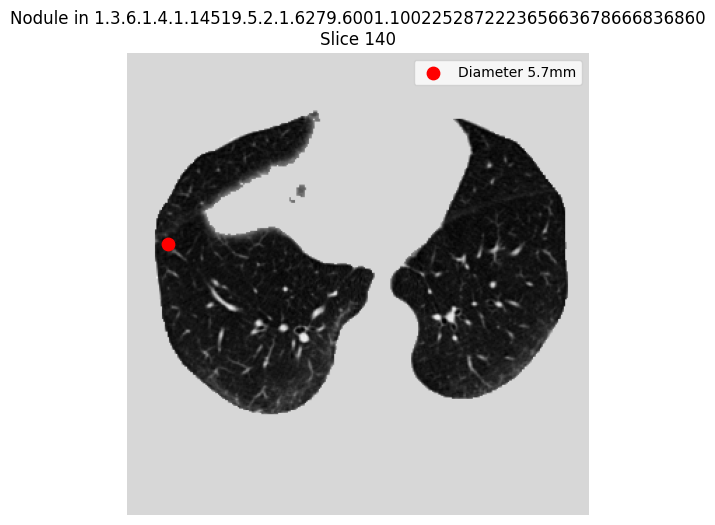

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd

# 📂 Paths
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
filtered_annots_path = "/media/farah/ADATA SD620/luna 16/final/filtered_annotations.csv"

# 📚 Load filtered annotations
annots = pd.read_csv(filtered_annots_path)

# 🎯 Pick one annotation (example: first one)
row = annots.iloc[0]
seriesuid = row['seriesuid']
z, y, x = int(row['coordZ_voxel']), int(row['coordY_voxel']), int(row['coordX_voxel'])
diameter = row['diameter_mm']

# 📖 Load scan
scan_path = os.path.join(normalized_scans_folder, f"{seriesuid}.npz")
scan = np.load(scan_path)['scan']

# 🎨 Plot slice
plt.figure(figsize=(6, 6))
plt.imshow(scan[z], cmap='gray')
plt.scatter(x, y, c='r', s=80, label=f'Diameter {diameter:.1f}mm')
plt.title(f'Nodule in {seriesuid}\nSlice {z}')
plt.legend()
plt.axis('off')
plt.show()


## Nodule Annotation Check

This plot shows a CT slice with a red dot marking the center of a detected nodule. The dot is placed using voxel coordinates derived from the LUNA16 annotations.

- The **red dot** marks the nodule location.
- The **label** shows its diameter in mm.
- The background is a grayscale lung CT slice.

This confirms our coordinate conversion works correctly and that the annotation is accurately placed within the lung region.


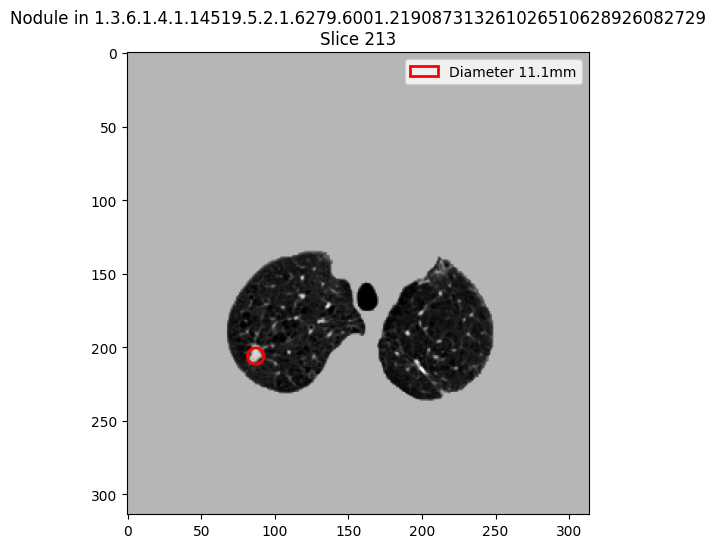

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random
import os

# 📂 Paths
filtered_annots_path = '/media/farah/ADATA SD620/luna 16/final/filtered_annotations.csv'
normalized_scans_folder = '/media/farah/ADATA SD620/luna 16/final/normalized_scans'

# 📚 Load filtered annotations
df = pd.read_csv(filtered_annots_path)

# 🎲 Pick a random nodule
random_idx = random.randint(0, len(df)-1)
nodule = df.iloc[random_idx]

# 📋 Extract info
seriesuid = nodule['seriesuid']
z = int(nodule['coordZ_voxel'])
y = int(nodule['coordY_voxel'])
x = int(nodule['coordX_voxel'])
diameter_mm = nodule['diameter_mm']

# 📂 Load the corresponding scan
scan_path = os.path.join(normalized_scans_folder, f"{seriesuid}.npz")
scan = np.load(scan_path)['scan']

# 🖼 Plot
fig, ax = plt.subplots(figsize=(6,6))
ax.imshow(scan[z], cmap='gray')

# 🔴 Draw the circle
circle = patches.Circle(
    (x, y),
    radius=diameter_mm / 2,  # because spacing = 1mm
    edgecolor='red',
    facecolor='none',
    linewidth=2
)
ax.add_patch(circle)

# 🏷 Add title and legend
ax.set_title(f'Nodule in {seriesuid}\nSlice {z}')
ax.legend([circle], [f"Diameter {diameter_mm:.1f}mm"], loc="upper right")

plt.show()


## Visualizing a Random Nodule

This slice shows a randomly selected lung nodule from the dataset. The red circle outlines the nodule using its diameter from the annotations.

- The **circle** represents the actual size (in mm).
- The **location** is based on converted voxel coordinates.
- This helps verify spatial alignment between scans and annotation data.


## 6. Create 3D Nodule Masks

### Goal:
To generate binary **3D masks** for each CT scan, where the voxels corresponding to nodules are marked as `1`, and all other voxels are `0`. These masks are essential for training segmentation models like 3D U-Net.

---

### What We Did:

-  **Loaded** each preprocessed CT scan (`.npz`) and its corresponding nodule annotations from the filtered CSV.
-  For each nodule:
  - Used the **voxel coordinates** `(z, y, x)` of the nodule center.
  - Calculated the **voxel radius** from the annotated nodule diameter.
  - Created a **3D spherical mask** using a Euclidean distance formula.
-  **Stored** the binary 3D mask as a compressed `.npz` file in the mask output folder.

---

### Output Folder:
All generated nodule masks are saved to:  
`/media/farah/ADATA SD620/luna 16/final/nodule_masks`

Each file is named the same as the corresponding scan and contains a variable:
- `mask` → a 3D NumPy array with shape matching the scan, containing values 0 (background) or 1 (nodule region).

---

### Result:
- One 3D binary mask was created for each of the **888** normalized CT scans.
- These masks align spatially with the scans and are ready for segmentation model training or evaluation.

---


In [52]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm

# 📂 Paths
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
masks_folder = "/media/farah/ADATA SD620/luna 16/final/nodule_masks"
filtered_annots_path = "/media/farah/ADATA SD620/luna 16/final/filtered_annotations.csv"

# 📚 Load annotations
annotations = pd.read_csv(filtered_annots_path)

# ✨ Create mask output folder
os.makedirs(masks_folder, exist_ok=True)

# 📋 List all scans
scan_files = [f for f in os.listdir(normalized_scans_folder) if f.endswith('.npz')]

# 🚀 Create masks
for scan_file in tqdm(scan_files, desc="Creating 3D masks"):
    seriesuid = scan_file.replace('.npz', '')
    scan_path = os.path.join(normalized_scans_folder, scan_file)
    scan_data = np.load(scan_path)
    scan = scan_data['scan']
    
    mask = np.zeros_like(scan, dtype=np.uint8)

    # 📌 Get nodules for this scan
    nodules = annotations[annotations['seriesuid'] == seriesuid]

    for _, nodule in nodules.iterrows():
        z, y, x = int(nodule['coordZ_voxel']), int(nodule['coordY_voxel']), int(nodule['coordX_voxel'])
        diameter_mm = nodule['diameter_mm']
        radius_voxels = int(np.round(diameter_mm / 2))

        # 3D sphere around (z, y, x)
        zz, yy, xx = np.ogrid[
            :mask.shape[0],
            :mask.shape[1],
            :mask.shape[2]
        ]
        distance = np.sqrt((zz - z)**2 + (yy - y)**2 + (xx - x)**2)
        mask[distance <= radius_voxels] = 1

    # 💾 Save the mask
    out_path = os.path.join(masks_folder, scan_file)
    np.savez_compressed(out_path, mask=mask)

print("✅ All 3D nodule masks created and saved!")


Creating 3D masks: 100%|██████████████████████| 888/888 [16:13<00:00,  1.10s/it]

✅ All 3D nodule masks created and saved!


🎯 Visualizing scan: 1.3.6.1.4.1.14519.5.2.1.6279.6001.404364125369979066736354549484


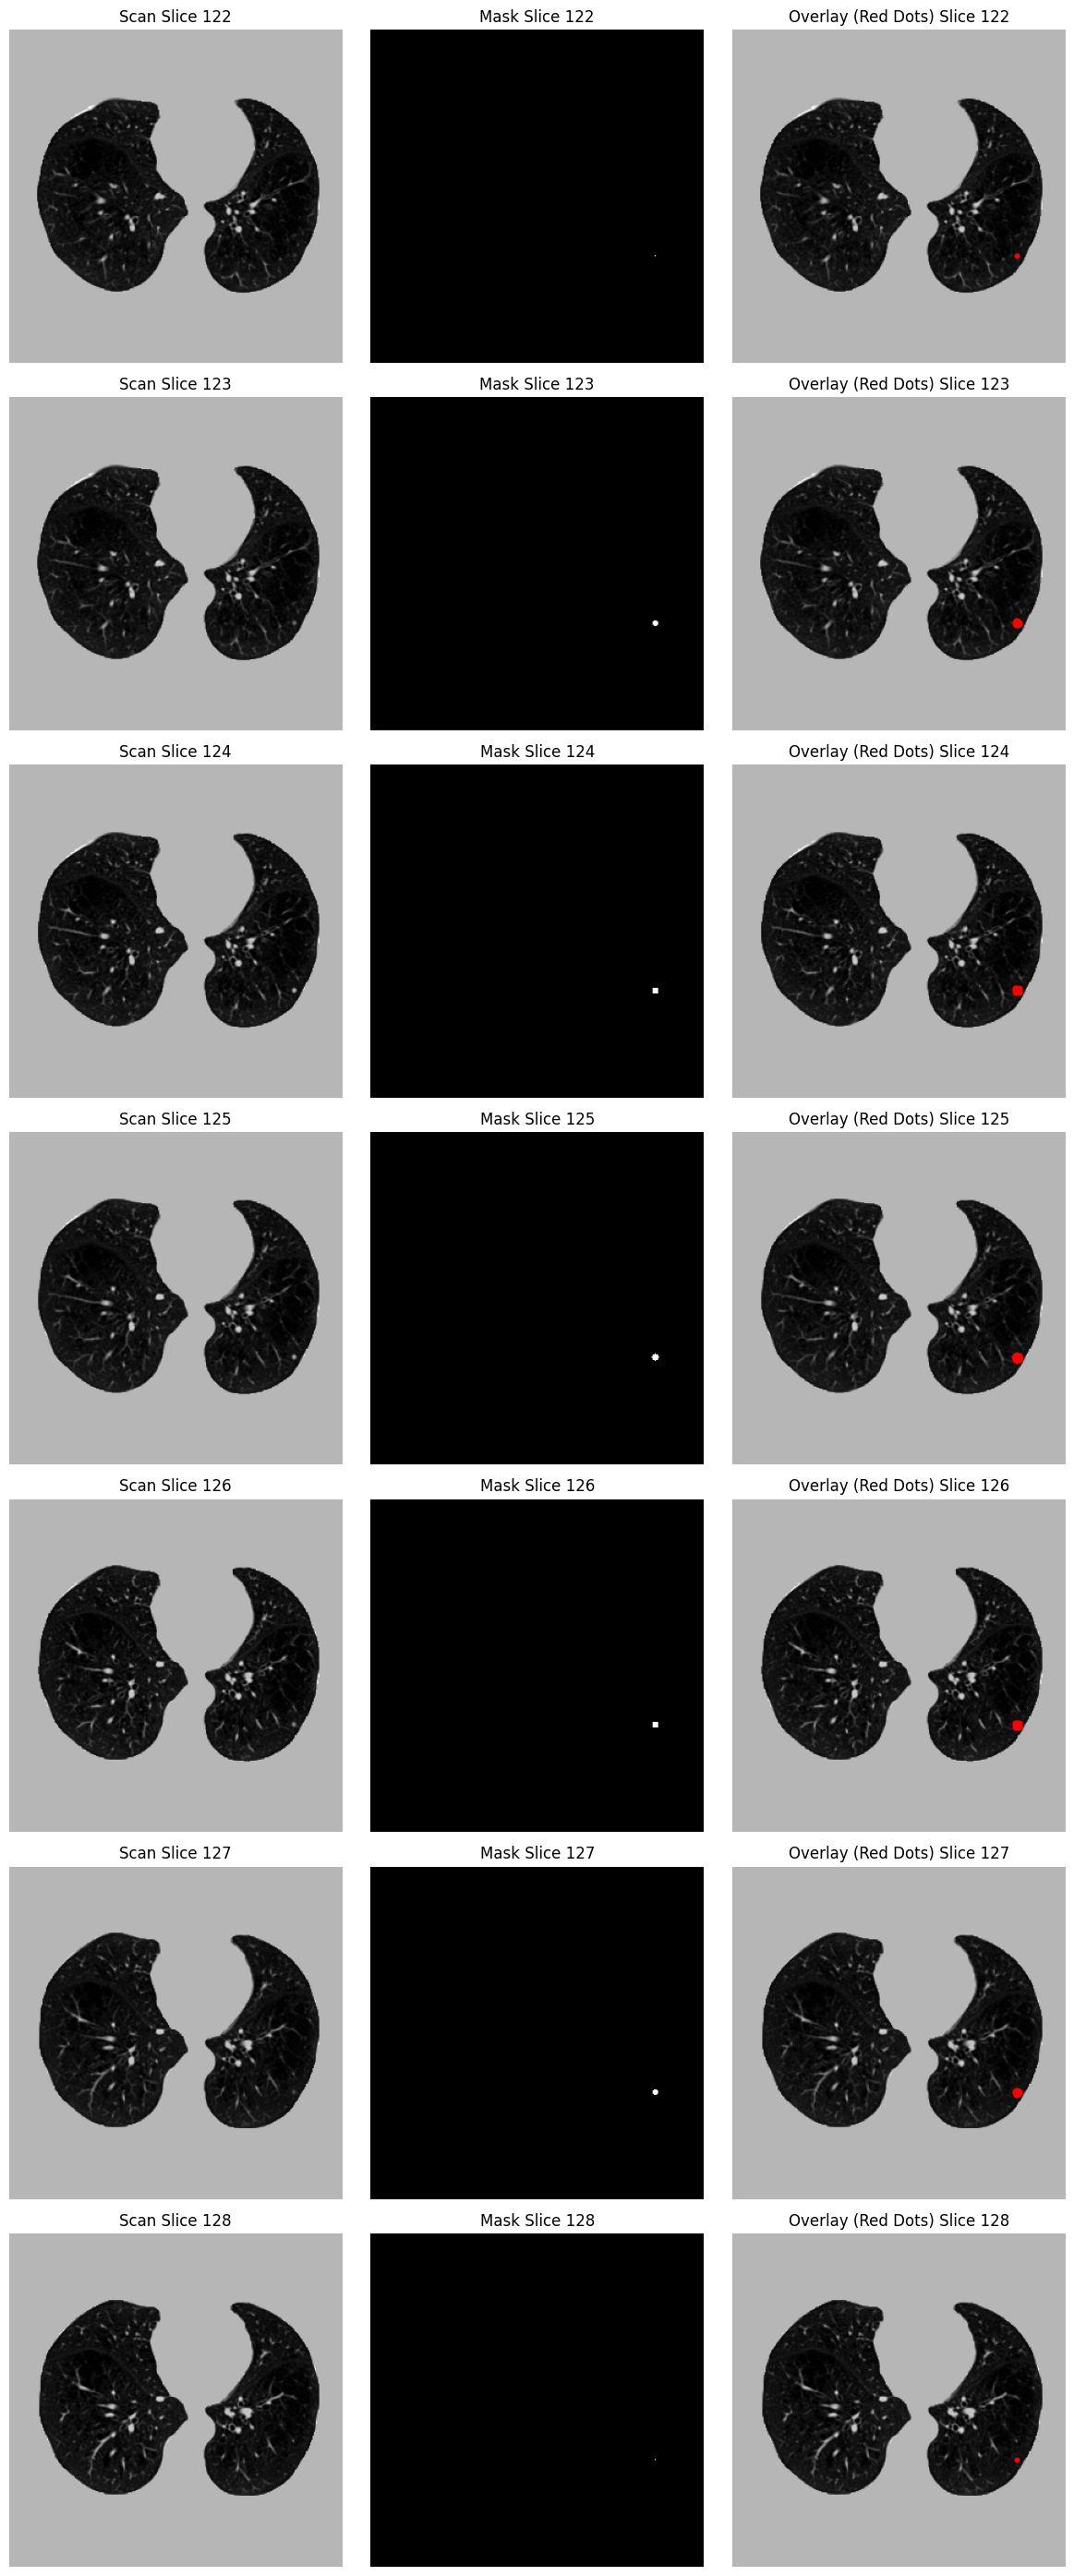

In [56]:
import numpy as np
import matplotlib.pyplot as plt
import os
import random

# 📂 Paths
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
nodule_masks_folder = "/media/farah/ADATA SD620/luna 16/final/nodule_masks"

# 📋 List available scans
scan_files = [f.replace('.npz', '') for f in os.listdir(normalized_scans_folder) if f.endswith('.npz')]

# 🎯 Function to pick random scan with nodules
def pick_random_scan_with_nodule(scan_files):
    while True:
        scan_file = random.choice(scan_files)
        mask_path = os.path.join(nodule_masks_folder, f"{scan_file}.npz")
        mask = np.load(mask_path)['mask']
        if np.sum(mask) > 0:
            return scan_file

# 🎲 Pick random scan
scan_file = pick_random_scan_with_nodule(scan_files)
print(f"🎯 Visualizing scan: {scan_file}")

# 📥 Load scan and mask
scan_path = os.path.join(normalized_scans_folder, f"{scan_file}.npz")
mask_path = os.path.join(nodule_masks_folder, f"{scan_file}.npz")

scan = np.load(scan_path)['scan']
mask = np.load(mask_path)['mask']

# 🎯 Pick slices with nodules
slices_with_nodule = np.unique(np.where(mask > 0)[0])
slices_to_plot = slices_with_nodule[::max(1, len(slices_with_nodule)//5)]

# 🎨 Plot
fig, axs = plt.subplots(len(slices_to_plot), 3, figsize=(12, 4 * len(slices_to_plot)))

for i, idx in enumerate(slices_to_plot):
    axs[i,0].imshow(scan[idx], cmap='gray')
    axs[i,0].set_title(f"Scan Slice {idx}")
    axs[i,0].axis('off')
    
    axs[i,1].imshow(mask[idx], cmap='gray')
    axs[i,1].set_title(f"Mask Slice {idx}")
    axs[i,1].axis('off')
    
    axs[i,2].imshow(scan[idx], cmap='gray')
    axs[i,2].scatter(
        np.where(mask[idx]>0)[1],  # X coords
        np.where(mask[idx]>0)[0],  # Y coords
        color='red', s=10  # size of dots
    )
    axs[i,2].set_title(f"Overlay (Red Dots) Slice {idx}")
    axs[i,2].axis('off')

plt.tight_layout()
plt.show()


### Nodule Mask Visualization

This figure shows:
- **Left**: Original CT scan slice.
- **Center**: Binary mask highlighting the nodule area.
- **Right**: Overlay of the mask on the scan (red dots).

This helps verify that the 3D spherical mask correctly aligns with visible nodules in the scan.


## 7. Extract 3D Patches Around Nodules (Positives)

We extract 3D patches (48³ voxels) centered around each annotated nodule using voxel coordinates from the annotations. Each patch is saved for training a nodule detector.

Boundary checks ensure patches stay within scan limits.

In [74]:
import os
import numpy as np
from tqdm import tqdm

# 📂 Folders
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
patches_output_folder = "/media/farah/ADATA SD620/luna 16/final/patches/positives"
os.makedirs(patches_output_folder, exist_ok=True)

# ⚙️ Settings
patch_size = 48  # Patch size (48x48x48)
half_size = patch_size // 2


# 🚀 Loop through each nodule annotation
for idx, row in tqdm(filtered_annots.iterrows(), total=len(filtered_annots), desc="Extracting positive patches"):
    try:
        uid = row['seriesuid']
        
        # Load scan
        scan_path = os.path.join(normalized_scans_folder, f"{uid}.npz")
        scan_data = np.load(scan_path)
        scan = scan_data['scan']
        
        # Voxel coordinates
        z, y, x = int(row['coordZ_voxel']), int(row['coordY_voxel']), int(row['coordX_voxel'])
        
        # Patch bounds
        z_min, z_max = z - half_size, z + half_size
        y_min, y_max = y - half_size, y + half_size
        x_min, x_max = x - half_size, x + half_size

        # Boundary check
        if (z_min < 0 or y_min < 0 or x_min < 0 or
            z_max > scan.shape[0] or
            y_max > scan.shape[1] or
            x_max > scan.shape[2]):
            print(f"⚠️ Patch for {uid} at ({z},{y},{x}) out of bounds, skipping.")
            continue
        
        # Extract patch
        patch = scan[z_min:z_max, y_min:y_max, x_min:x_max]
        
        # Save patch
        patch_filename = os.path.join(patches_output_folder, f"{uid}_{idx}_patch.npz")
        np.savez_compressed(patch_filename, patch=patch)

    except Exception as e:
        print(f"⚠️ Error extracting patch for index {idx}: {e}")

print("✅ Done extracting positive patches!")


Extracting positive patches:   6%|▋           | 68/1186 [00:29<07:50,  2.38it/s]

⚠️ Patch for 1.3.6.1.4.1.14519.5.2.1.6279.6001.119304665257760307862874140576 at (53,162,19) out of bounds, skipping.


Extracting positive patches:   7%|▊           | 86/1186 [00:38<08:13,  2.23it/s]

⚠️ Patch for 1.3.6.1.4.1.14519.5.2.1.6279.6001.123697637451437522065941162930 at (215,-157,-266) out of bounds, skipping.


Extracting positive patches:   9%|▉          | 103/1186 [00:48<08:13,  2.19it/s]

...

⚠️ Patch for 1.3.6.1.4.1.14519.5.2.1.6279.6001.964952370561266624992539111877 at (255,-139,-257) out of bounds, skipping.


Extracting positive patches:  99%|█████████▉| 1176/1186 [09:20<00:04,  2.19it/s]

⚠️ Patch for 1.3.6.1.4.1.14519.5.2.1.6279.6001.964952370561266624992539111877 at (253,-169,-261) out of bounds, skipping.


Extracting positive patches: 100%|██████████| 1186/1186 [09:26<00:00,  2.10it/s]

✅ Done extracting positive patches!


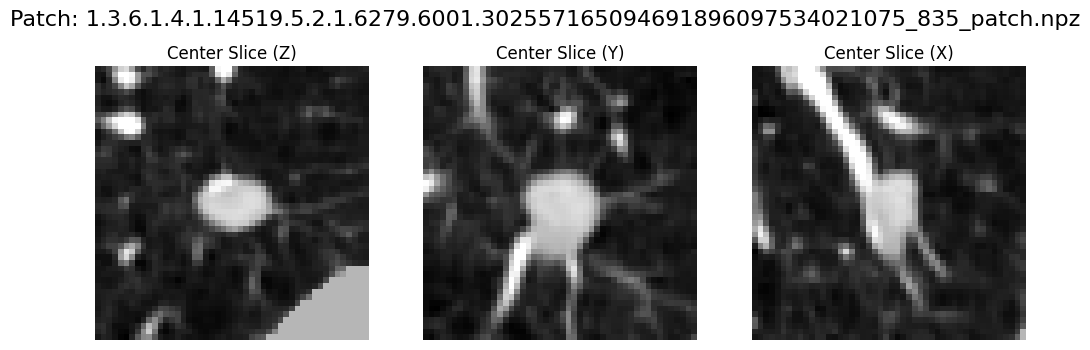

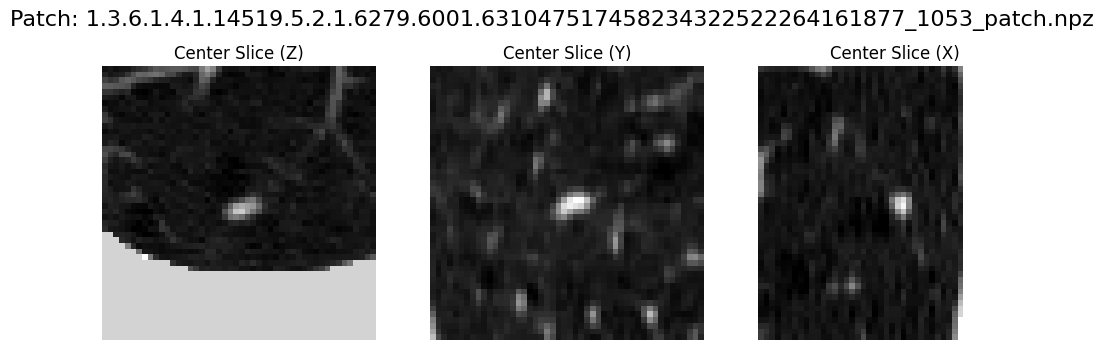

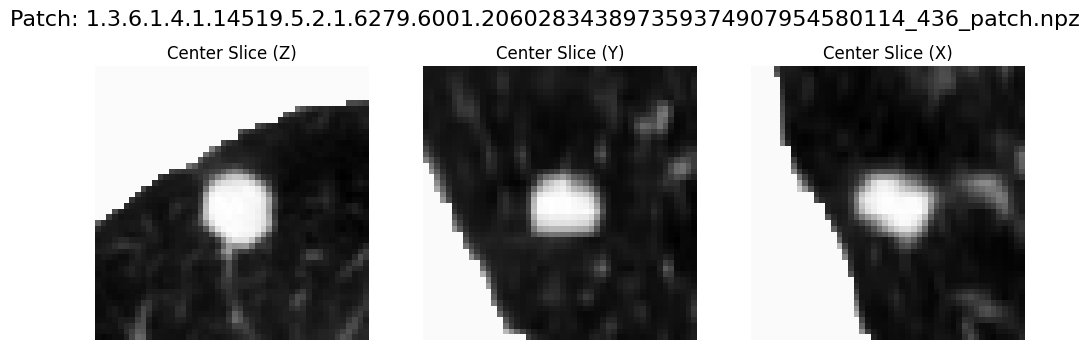

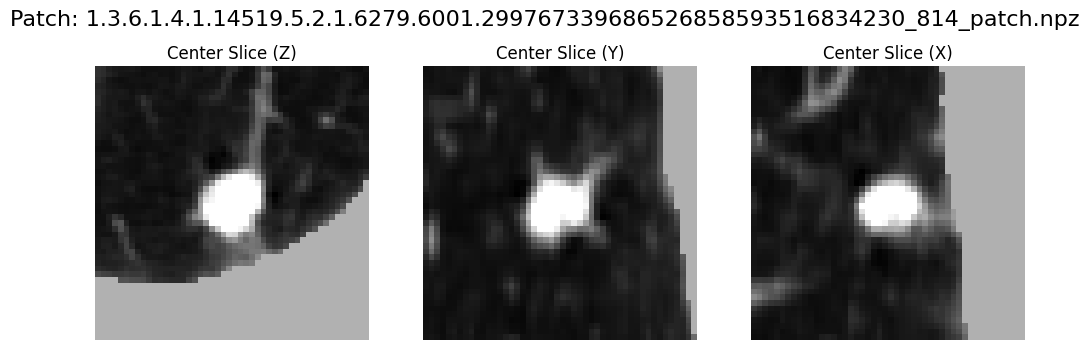

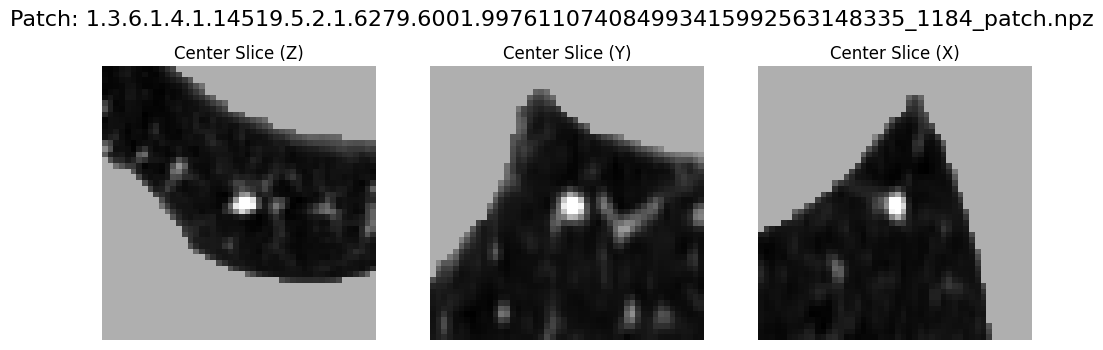

In [76]:
import os
import numpy as np
import matplotlib.pyplot as plt
import random

# 📂 Folder where you saved your patches
patches_folder = "/media/farah/ADATA SD620/luna 16/final/patches/positives"

# 🔀 Randomly pick some patches
patch_files = random.sample(os.listdir(patches_folder), 5)  # Pick 5 random patches

for patch_file in patch_files:
    patch_path = os.path.join(patches_folder, patch_file)
    patch = np.load(patch_path)

    # Just to be safe, if you saved as npz
    if isinstance(patch, np.lib.npyio.NpzFile):
        patch = patch['patch']

    # 🎯 Show 3 central slices (Z, Y, X)
    center = [s // 2 for s in patch.shape]
    
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    fig.suptitle(f'Patch: {patch_file}', fontsize=16)

    axes[0].imshow(patch[center[0], :, :], cmap='gray')
    axes[0].set_title('Center Slice (Z)')
    
    axes[1].imshow(patch[:, center[1], :], cmap='gray')
    axes[1].set_title('Center Slice (Y)')
    
    axes[2].imshow(patch[:, :, center[2]], cmap='gray')
    axes[2].set_title('Center Slice (X)')
    
    for ax in axes:
        ax.axis('off')
        
    plt.show()


In [77]:
import os

positives_folder = "/media/farah/ADATA SD620/luna 16/final/patches/positives"
num_positive_patches = len([f for f in os.listdir(positives_folder) if f.endswith('.npz')])

print(f"✅ Total positive patches: {num_positive_patches}")


✅ Total positive patches: 1155


In [100]:
import os
import numpy as np
import random
from tqdm import tqdm

# 📂 Folders
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
nodule_masks_folder = "/media/farah/ADATA SD620/luna 16/final/nodule_masks"
patches_output_folder = "/media/farah/ADATA SD620/luna 16/final/patches/test_positive_patches"
os.makedirs(patches_output_folder, exist_ok=True)

# ⚙️ Settings
patch_size = 48
half_size = patch_size // 2

# ✨ Only work on 5 random annotations
sampled_annots = filtered_annots.sample(5, random_state=42)

for idx, row in tqdm(sampled_annots.iterrows(), total=len(sampled_annots), desc="Extracting test positive patches"):
    try:
        uid = row['seriesuid']
        
        scan_path = os.path.join(normalized_scans_folder, f"{uid}.npz")
        if not os.path.exists(scan_path):
            print("⚠️ Missing scan", uid, "skipping.")
            continue
        
        scan_data = np.load(scan_path)
        scan = scan_data['scan']

        z, y, x = int(row['coordZ_voxel']), int(row['coordY_voxel']), int(row['coordX_voxel'])
        
        z_min, z_max = z - half_size, z + half_size
        y_min, y_max = y - half_size, y + half_size
        x_min, x_max = x - half_size, x + half_size

        if (z_min < 0 or y_min < 0 or x_min < 0 or
            z_max > scan.shape[0] or
            y_max > scan.shape[1] or
            x_max > scan.shape[2]):
            print("⚠️ Patch for", uid, "at", (z, y, x), "out of bounds, skipping.")
            continue

        patch = scan[z_min:z_max, y_min:y_max, x_min:x_max]

        patch_filename = os.path.join(patches_output_folder, f"{uid}_{idx}_patch.npz")
        np.savez_compressed(patch_filename, patch=patch)

    except Exception as e:
        print("⚠️ Error extracting patch for index", idx, ":", e)

print("\n✅ Test extraction done!")


Extracting test positive patches: 100%|███████████| 5/5 [00:03<00:00,  1.65it/s]


✅ Test extraction done!


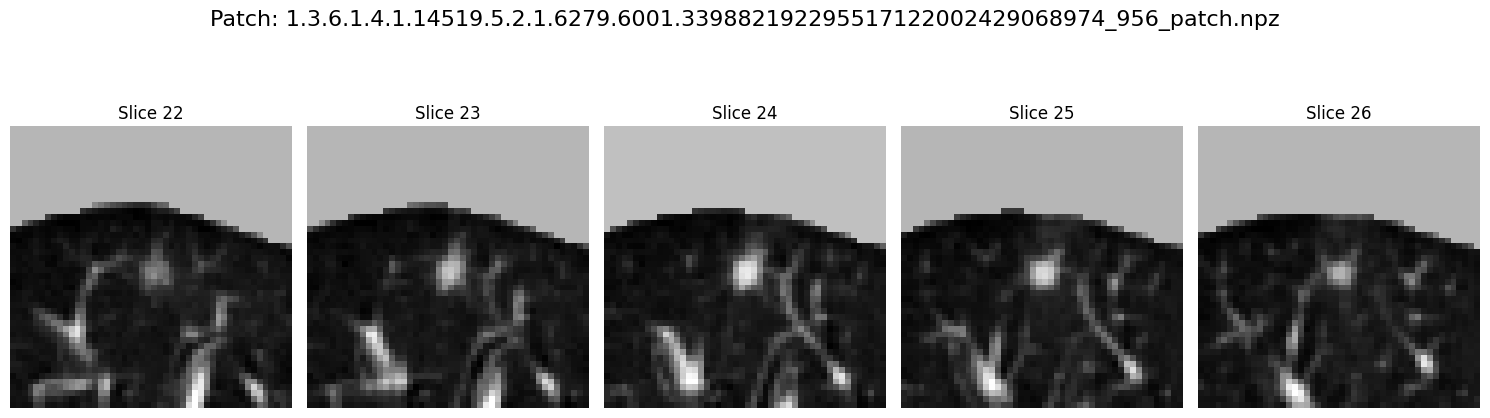

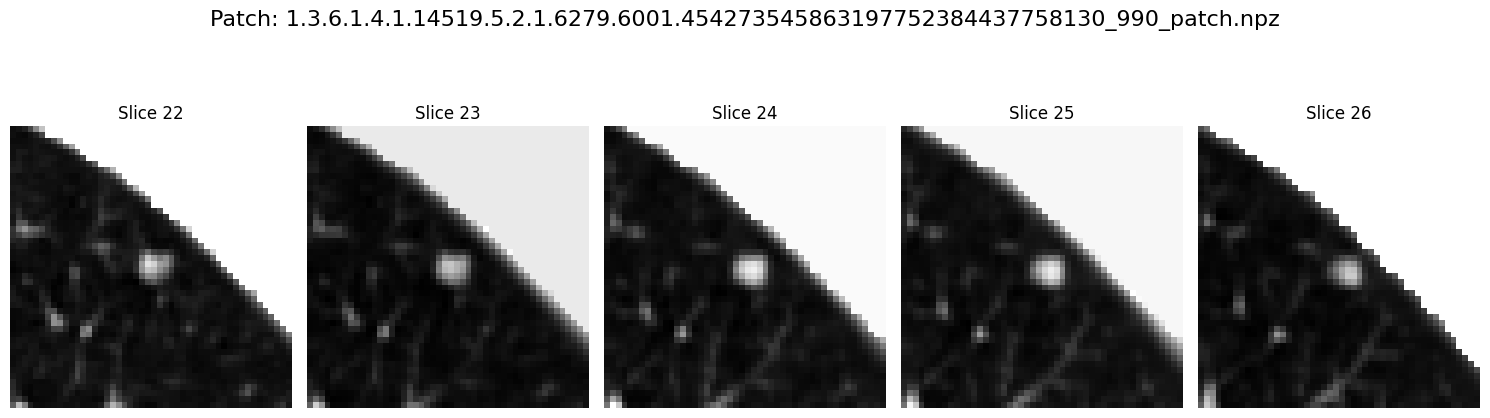

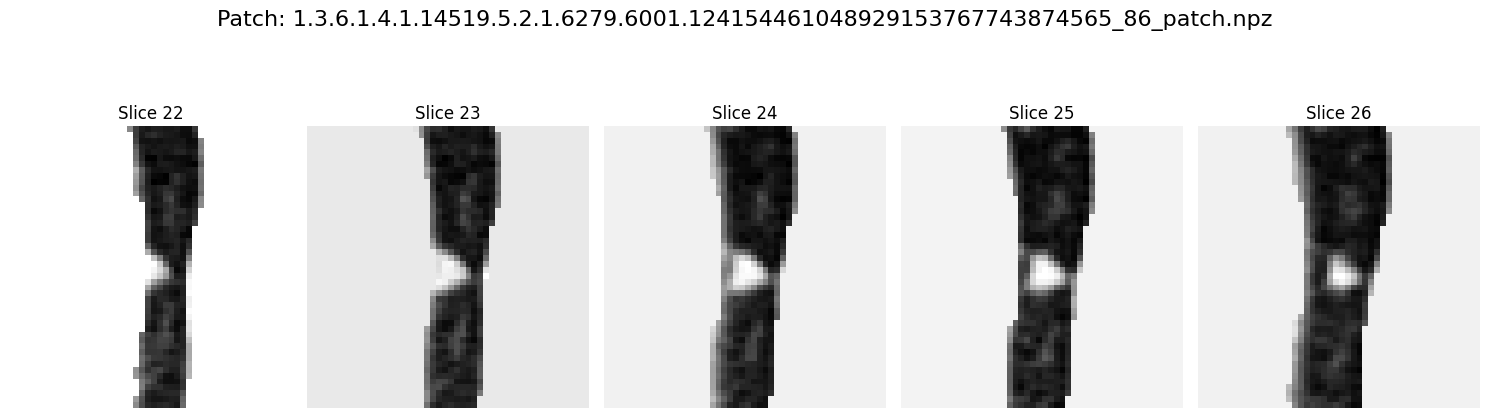

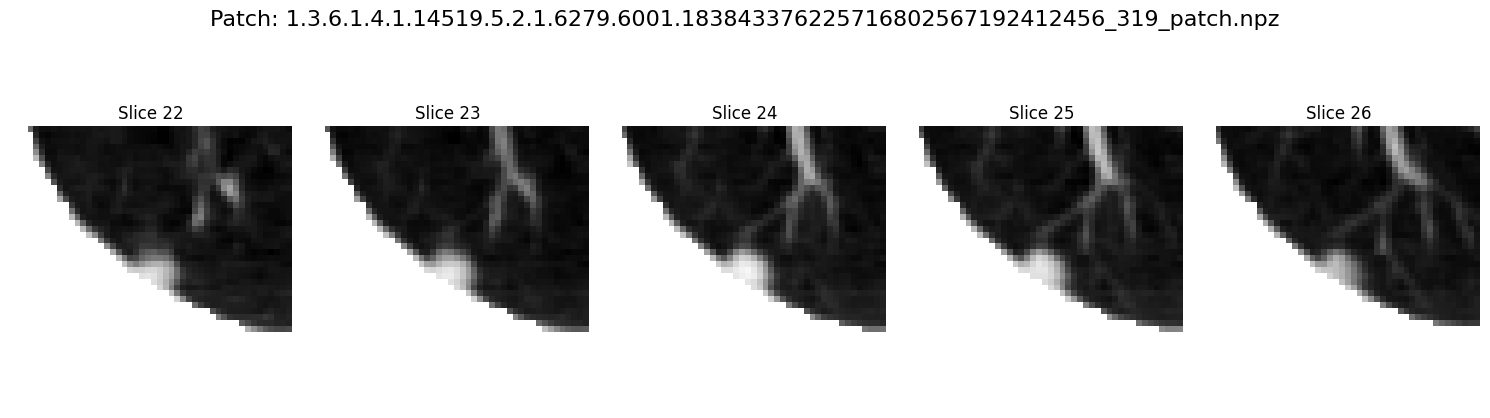

In [102]:
import numpy as np
import os
import matplotlib.pyplot as plt
import random

# 📂 Folder where your test patches are saved
patches_folder ="/media/farah/ADATA SD620/luna 16/final/patches/test_positive_patches"

# 📋 List all patch files
patch_files = [f for f in os.listdir(patches_folder) if f.endswith(".npz")]

# 🎯 Randomly pick 4 patches
sampled_patches = random.sample(patch_files, min(4, len(patch_files)))

for patch_file in sampled_patches:
    patch_path = os.path.join(patches_folder, patch_file)
    patch_data = np.load(patch_path)
    patch = patch_data['patch']

    # 🖼 Plot center slices
    fig, axes = plt.subplots(1, 5, figsize=(15, 5))
    fig.suptitle(f"Patch: {patch_file}", fontsize=16)

    center_slice = patch.shape[0] // 2
    slices = np.linspace(center_slice - 2, center_slice + 2, 5).astype(int)

    for ax, idx in zip(axes, slices):
        ax.imshow(patch[idx], cmap='gray')
        ax.set_title(f"Slice {idx}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()


### Test Positive Patch Extraction & Visualization

To visually validate patch extraction, we randomly sample 5 annotated nodules and extract centered 3D patches (48×48×48 voxels) from their respective scans.

We then visualize 5 axial slices (centered around the patch center) to ensure that the nodule is present and well-centered.

This helps confirm patch correctness before large-scale processing.


In [103]:
import os
import numpy as np
from tqdm import tqdm

# 📂 Folders
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
nodule_masks_folder = "/media/farah/ADATA SD620/luna 16/final/nodule_masks"
patches_output_folder = "/media/farah/ADATA SD620/luna 16/final/patches/positives_test"  # ✅ New temp folder for testing
os.makedirs(patches_output_folder, exist_ok=True)

# ⚙️ Settings
patch_size = 48
half_size = patch_size // 2

# 🎯 Select a few annotations only
filtered_annots_sample = filtered_annots.sample(n=5, random_state=42)  # Pick 5 random samples

# 🚀 Loop through small sample
for idx, row in tqdm(filtered_annots_sample.iterrows(), total=len(filtered_annots_sample), desc="Extracting TEST positive patches"):
    try:
        uid = row['seriesuid']
        
        # Load scan
        scan_path = os.path.join(normalized_scans_folder, f"{uid}.npz")
        scan_data = np.load(scan_path)
        scan = scan_data['scan']
        
        # Load corresponding mask
        mask_path = os.path.join(nodule_masks_folder, f"{uid}.npz")
        mask_data = np.load(mask_path)
        mask = mask_data['mask']

        # Voxel coordinates
        z, y, x = int(row['coordZ_voxel']), int(row['coordY_voxel']), int(row['coordX_voxel'])
        
        # Patch bounds
        z_min, z_max = z - half_size, z + half_size
        y_min, y_max = y - half_size, y + half_size
        x_min, x_max = x - half_size, x + half_size

        # Boundary check
        if (z_min < 0 or y_min < 0 or x_min < 0 or
            z_max > scan.shape[0] or
            y_max > scan.shape[1] or
            x_max > scan.shape[2]):
            print(f"⚠️ Patch for {uid} at ({z},{y},{x}) out of bounds, skipping.")
            continue
        
        # Extract patches
        patch = scan[z_min:z_max, y_min:y_max, x_min:x_max]
        patch_mask = mask[z_min:z_max, y_min:y_max, x_min:x_max]

        # Save both
        patch_filename = os.path.join(patches_output_folder, f"{uid}_{idx}_patch.npz")
        np.savez_compressed(patch_filename, patch=patch, mask=patch_mask)

    except Exception as e:
        print(f"⚠️ Error extracting patch for index {idx}: {e}")

print("✅ Test extraction done!")


Extracting TEST positive patches: 100%|███████████| 5/5 [00:03<00:00,  1.38it/s]

✅ Test extraction done!


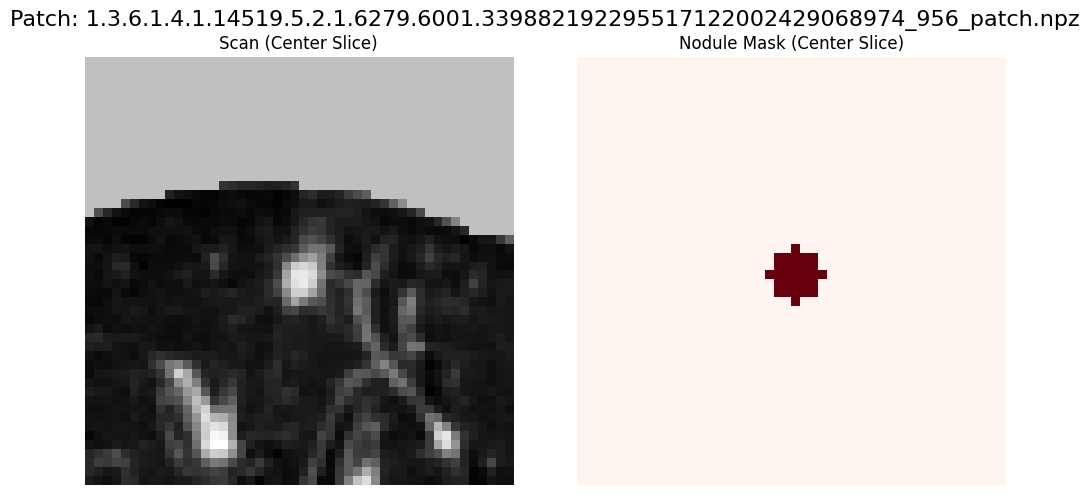

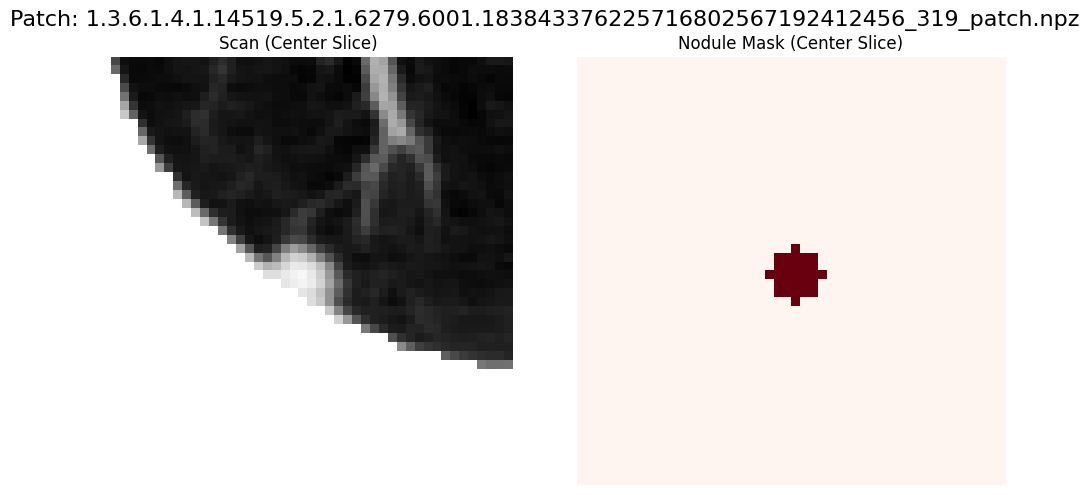

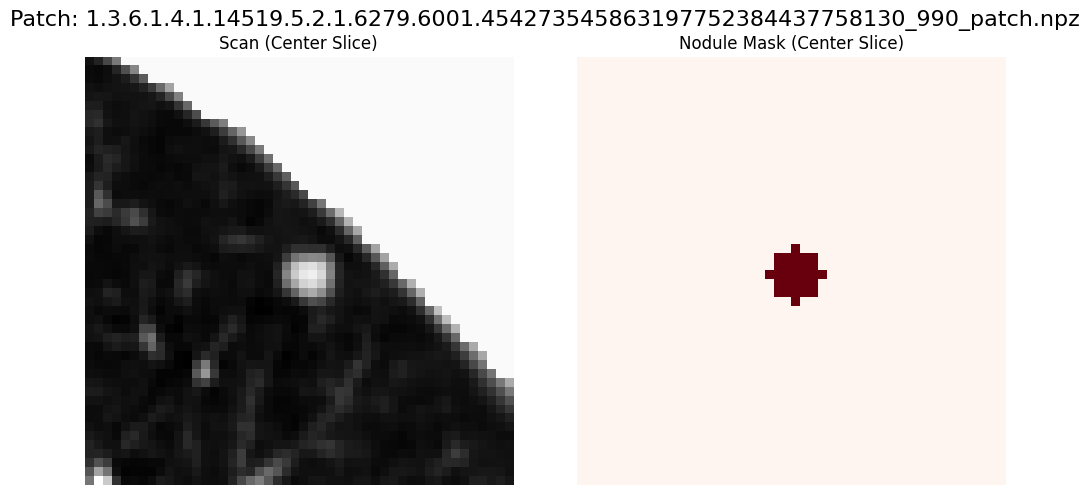

In [104]:
import os
import numpy as np
import matplotlib.pyplot as plt
import random

# 📂 Path to the test patches
test_patches_folder = "/media/farah/ADATA SD620/luna 16/final/patches/positives_test"

# 📋 List available patches
patch_files = [f for f in os.listdir(test_patches_folder) if f.endswith('.npz')]

# 🎯 Pick a few random patches
sampled_files = random.sample(patch_files, min(3, len(patch_files)))  # Pick 3 random ones

# 🖼 Plot each patch
for patch_file in sampled_files:
    patch_path = os.path.join(test_patches_folder, patch_file)
    data = np.load(patch_path)
    
    patch = data['patch']
    mask = data['mask']

    center = patch.shape[0] // 2  # Middle slice

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f"Patch: {patch_file}", fontsize=16)

    axes[0].imshow(patch[center], cmap='gray')
    axes[0].set_title("Scan (Center Slice)")
    axes[0].axis('off')

    axes[1].imshow(mask[center], cmap='Reds')
    axes[1].set_title("Nodule Mask (Center Slice)")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()


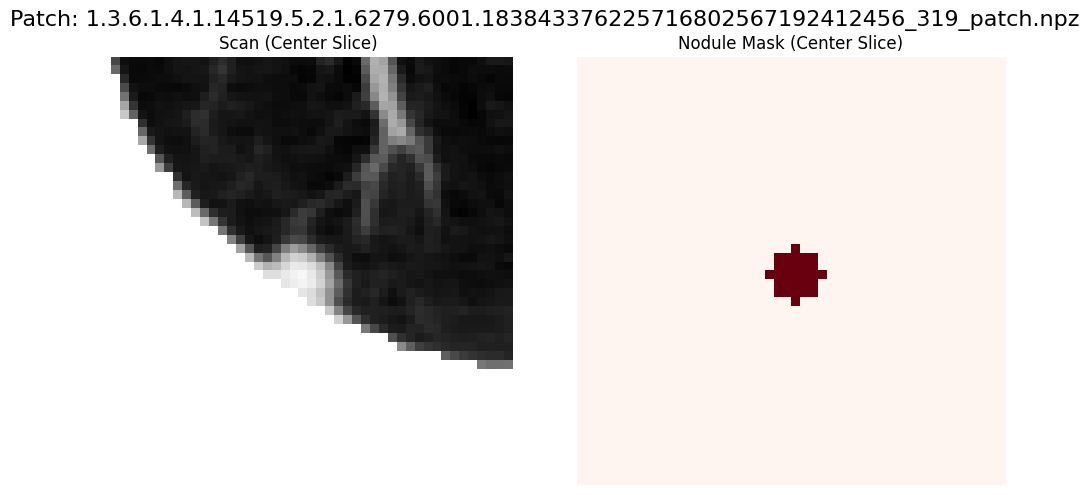

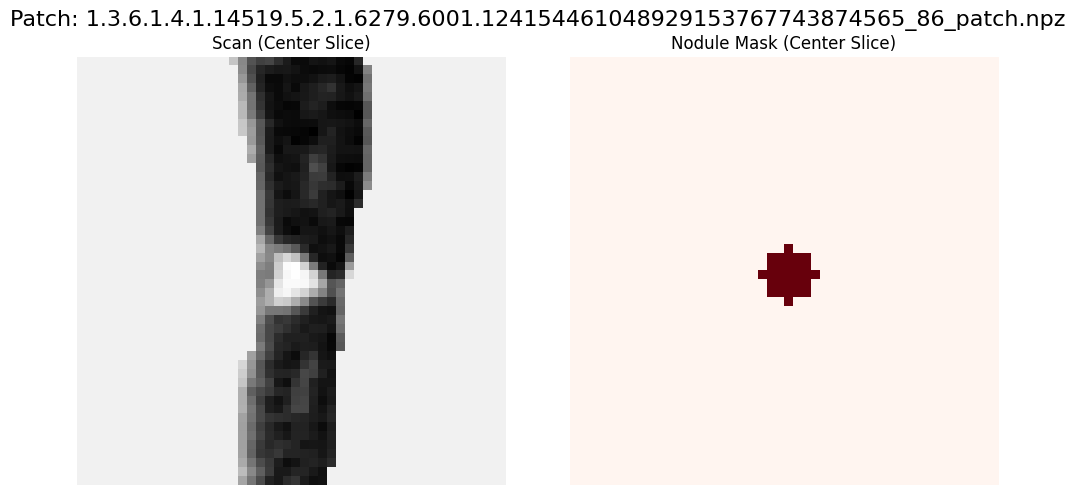

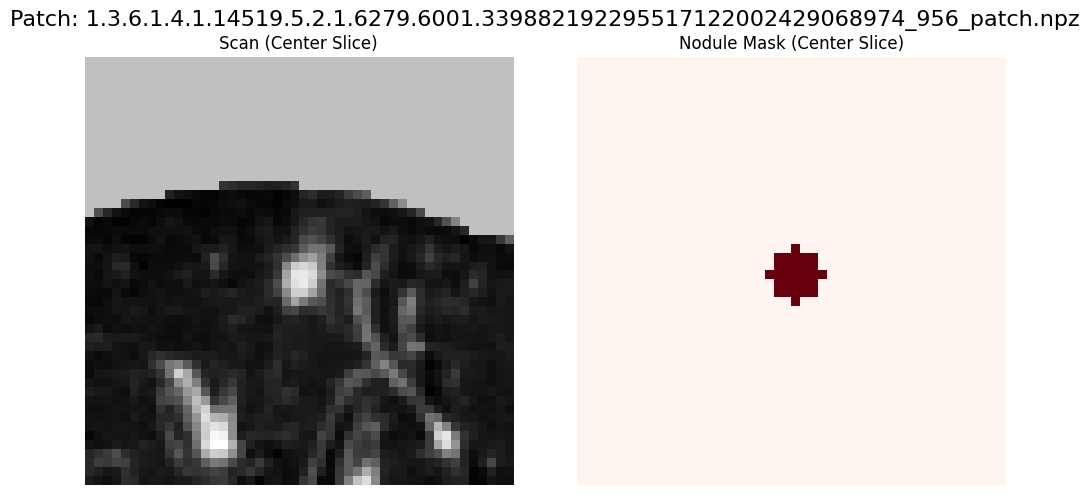

In [107]:
import os
import numpy as np
import matplotlib.pyplot as plt
import random

# 📂 Path to the test patches
test_patches_folder = "/media/farah/ADATA SD620/luna 16/final/patches/positives_test"

# 📋 List available patches
patch_files = [f for f in os.listdir(test_patches_folder) if f.endswith('.npz')]

# 🎯 Pick a few random patches
sampled_files = random.sample(patch_files, min(3, len(patch_files)))  # Pick 3 random ones

# 🖼 Plot each patch
for patch_file in sampled_files:
    patch_path = os.path.join(test_patches_folder, patch_file)
    data = np.load(patch_path)
    
    patch = data['patch']
    mask = data['mask']

    center = patch.shape[0] // 2  # Middle slice

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f"Patch: {patch_file}", fontsize=16)

    axes[0].imshow(patch[center], cmap='gray')
    axes[0].set_title("Scan (Center Slice)")
    axes[0].axis('off')

    axes[1].imshow(mask[center], cmap='Reds')
    axes[1].set_title("Nodule Mask (Center Slice)")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()


In [113]:
import os
import numpy as np
from tqdm import tqdm

# 📂 Folders
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
nodule_masks_folder = "/media/farah/ADATA SD620/luna 16/final/nodule_masks"
patches_output_folder = "/media/farah/ADATA SD620/luna 16/final/patches/positives"
os.makedirs(patches_output_folder, exist_ok=True)

# ⚙️ Settings
patch_size = 48
half_size = patch_size // 2

# 🚀 Loop through all annotations
for idx, row in tqdm(filtered_annots.iterrows(), total=len(filtered_annots), desc="Extracting ALL positive patches"):
    try:
        uid = row['seriesuid']

        # Load scan
        scan_path = os.path.join(normalized_scans_folder, f"{uid}.npz")
        scan_data = np.load(scan_path)
        scan = scan_data['scan']
        
        # Load mask
        mask_path = os.path.join(nodule_masks_folder, f"{uid}.npz")
        if not os.path.exists(mask_path):
            print(f"⚠️ Mask missing for {uid}, skipping...")
            continue
        mask_data = np.load(mask_path)
        mask = mask_data['mask']

        
        
        # Voxel coordinates
        z, y, x = int(row['coordZ_voxel']), int(row['coordY_voxel']), int(row['coordX_voxel'])

        # Patch bounds
        z_min, z_max = z - half_size, z + half_size
        y_min, y_max = y - half_size, y + half_size
        x_min, x_max = x - half_size, x + half_size

        # Boundary check
        if (z_min < 0 or y_min < 0 or x_min < 0 or
            z_max > scan.shape[0] or
            y_max > scan.shape[1] or
            x_max > scan.shape[2]):
            print(f"⚠️ Patch for {uid} at ({z},{y},{x}) out of bounds, skipping.")
            continue

        # Extract patch + mask
        patch = scan[z_min:z_max, y_min:y_max, x_min:x_max]
        mask_patch = mask[z_min:z_max, y_min:y_max, x_min:x_max]

        # Save both
        patch_filename = os.path.join(patches_output_folder, f"{uid}_{idx}_patch.npz")
        np.savez_compressed(patch_filename, patch=patch, mask=mask_patch)

    except Exception as e:
        print(f"⚠️ Error extracting patch for index {idx}: {e}")

print("\n✅ Done extracting ALL positive patches!")


Extracting ALL positive patches:   6%|▍       | 68/1186 [00:46<12:08,  1.54it/s]

⚠️ Patch for 1.3.6.1.4.1.14519.5.2.1.6279.6001.119304665257760307862874140576 at (53,162,19) out of bounds, skipping.


Extracting ALL positive patches:   7%|▌       | 86/1186 [01:00<13:06,  1.40it/s]

⚠️ Patch for 1.3.6.1.4.1.14519.5.2.1.6279.6001.123697637451437522065941162930 at (215,-157,-266) out of bounds, skipping.


Extracting ALL positive patches:   9%|▌      | 103/1186 [01:15<11:27,  1.58it/s]

...

⚠️ Patch for 1.3.6.1.4.1.14519.5.2.1.6279.6001.964952370561266624992539111877 at (255,-139,-257) out of bounds, skipping.


Extracting ALL positive patches:  99%|█████▉| 1176/1186 [11:45<00:04,  2.09it/s]

⚠️ Patch for 1.3.6.1.4.1.14519.5.2.1.6279.6001.964952370561266624992539111877 at (253,-169,-261) out of bounds, skipping.


Extracting ALL positive patches: 100%|██████| 1186/1186 [11:51<00:00,  1.67it/s]



✅ Done extracting ALL positive patches!


## 8. Sample Negative Patches (inside lung regions, away from nodules)

We took random 3D patches from regions without nodules to teach the model what "normal lung" tissue looks like. Ensure negative patches are sufficiently far from nodules to avoid confusion.

In [86]:
import os
import numpy as np
import random
from tqdm import tqdm
import matplotlib.pyplot as plt

# 📂 Paths
normalized_scans_folder = "/media/farah/ADATA SD620/luna 16/final/normalized_scans"
nodule_masks_folder = "/media/farah/ADATA SD620/luna 16/final/nodule_masks"
negatives_output_folder = "/media/farah/ADATA SD620/luna 16/final/patches/negatives"
os.makedirs(negatives_output_folder, exist_ok=True)

# ⚙️ Settings
patch_size = 48
half_size = patch_size // 2
distance_threshold = 30  # Minimum distance from any nodule
max_attempts = 500
std_threshold = 50     # Minimum std in HU
mean_threshold = -850  # Minimum mean HU
neg_to_pos_ratio = 2   # 📈 1 positive : 2 negatives

# 🗺 Mapping positives
positives_centers = {}  # {seriesuid: [ (z,y,x), (z,y,x), ... ]}

for idx, row in filtered_annots.iterrows():
    uid = row['seriesuid']
    center = (int(row['coordZ_voxel']), int(row['coordY_voxel']), int(row['coordX_voxel']))
    if uid not in positives_centers:
        positives_centers[uid] = []
    positives_centers[uid].append(center)

print(f"✅ Positive mapping ready ({len(positives_centers)} scans have positives).")

# 🛠 Helper function
def sample_negative_patches(scan_path, seriesuid, positive_coords, num_negatives):
    try:
        scan_data = np.load(scan_path)
        scan = scan_data['scan']
        
        # De-normalize to HU
        scan = (scan * 1400) - 1000

        # Simple lung mask
        lung_mask = (scan > -1000) & (scan < -700)
        lung_voxels = np.argwhere(lung_mask)

        if len(lung_voxels) == 0:
            return f"⚠️ No lung voxels in {seriesuid}, skipping."

        negatives_collected = 0
        attempts = 0

        while negatives_collected < num_negatives and attempts < max_attempts:
            attempts += 1
            idx = np.random.choice(len(lung_voxels))
            center_z, center_y, center_x = lung_voxels[idx]

            # Check distance to all nodules
            if any(np.linalg.norm(np.array([center_z, center_y, center_x]) - np.array(nodule)) < distance_threshold for nodule in positive_coords):
                continue

            z_min, z_max = center_z - half_size, center_z + half_size
            y_min, y_max = center_y - half_size, center_y + half_size
            x_min, x_max = center_x - half_size, center_x + half_size

            if z_min < 0 or y_min < 0 or x_min < 0 or z_max > scan.shape[0] or y_max > scan.shape[1] or x_max > scan.shape[2]:
                continue

            patch = scan[z_min:z_max, y_min:y_max, x_min:x_max]

            # Quality check
            if np.mean(patch) < mean_threshold or np.std(patch) < std_threshold:
                continue

            patch_filename = os.path.join(negatives_output_folder, f"{seriesuid}_negative_{negatives_collected}.npz")
            np.savez_compressed(patch_filename, patch=patch)

            negatives_collected += 1

        return f"✅ {seriesuid}: {negatives_collected} negatives collected."

    except Exception as e:
        return f"⚠️ Error in {seriesuid}: {e}"

# 🚀 Main Loop
all_scan_files = [f for f in os.listdir(normalized_scans_folder) if f.endswith('.npz')]

for scan_file in tqdm(all_scan_files, desc="Sampling Negatives"):
    seriesuid = scan_file.replace('.npz', '')
    positive_coords = positives_centers.get(seriesuid, [])
    
    num_positives = len(positive_coords)
    num_negatives = num_positives * neg_to_pos_ratio

    if num_positives == 0:
        continue  # Skip scans with no nodules

    scan_path = os.path.join(normalized_scans_folder, scan_file)
    result = sample_negative_patches(scan_path, seriesuid, positive_coords, num_negatives)
    print(result)

print("\n✅ Finished sampling negative patches!")



✅ Positive mapping ready (601 scans have positives).


Sampling Negatives:   0%|                       | 1/888 [00:00<11:05,  1.33it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860: 4 negatives collected.


Sampling Negatives:   0%|                       | 3/888 [00:01<05:40,  2.60it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793540579077826395208: 2 negatives collected.


...

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.822128649427327893802314908658: 2 negatives collected.


Sampling Negatives: 100%|████████████████████▉| 885/888 [07:54<00:01,  1.64it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.866845763956586959109892274084: 2 negatives collected.


Sampling Negatives: 100%|█████████████████████| 888/888 [07:55<00:00,  1.87it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.955688628308192728558382581802: 10 negatives collected.

✅ Finished sampling negative patches!


Sampling Negatives (Test Subset):  20%|██▏        | 1/5 [00:00<00:02,  1.47it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860: 2 negatives collected.


Sampling Negatives (Test Subset):  40%|████▍      | 2/5 [00:01<00:02,  1.47it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100332161840553388986847034053: 2 negatives collected.


Sampling Negatives (Test Subset):  60%|██████▌    | 3/5 [00:01<00:01,  1.65it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793540579077826395208: 2 negatives collected.


Sampling Negatives (Test Subset):  80%|████████▊  | 4/5 [00:02<00:00,  1.66it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100530488926682752765845212286: 2 negatives collected.


Sampling Negatives (Test Subset): 100%|███████████| 5/5 [00:03<00:00,  1.60it/s]

✅ 1.3.6.1.4.1.14519.5.2.1.6279.6001.100620385482151095585000946543: 2 negatives collected.

✅ Finished sampling negatives for test subset!


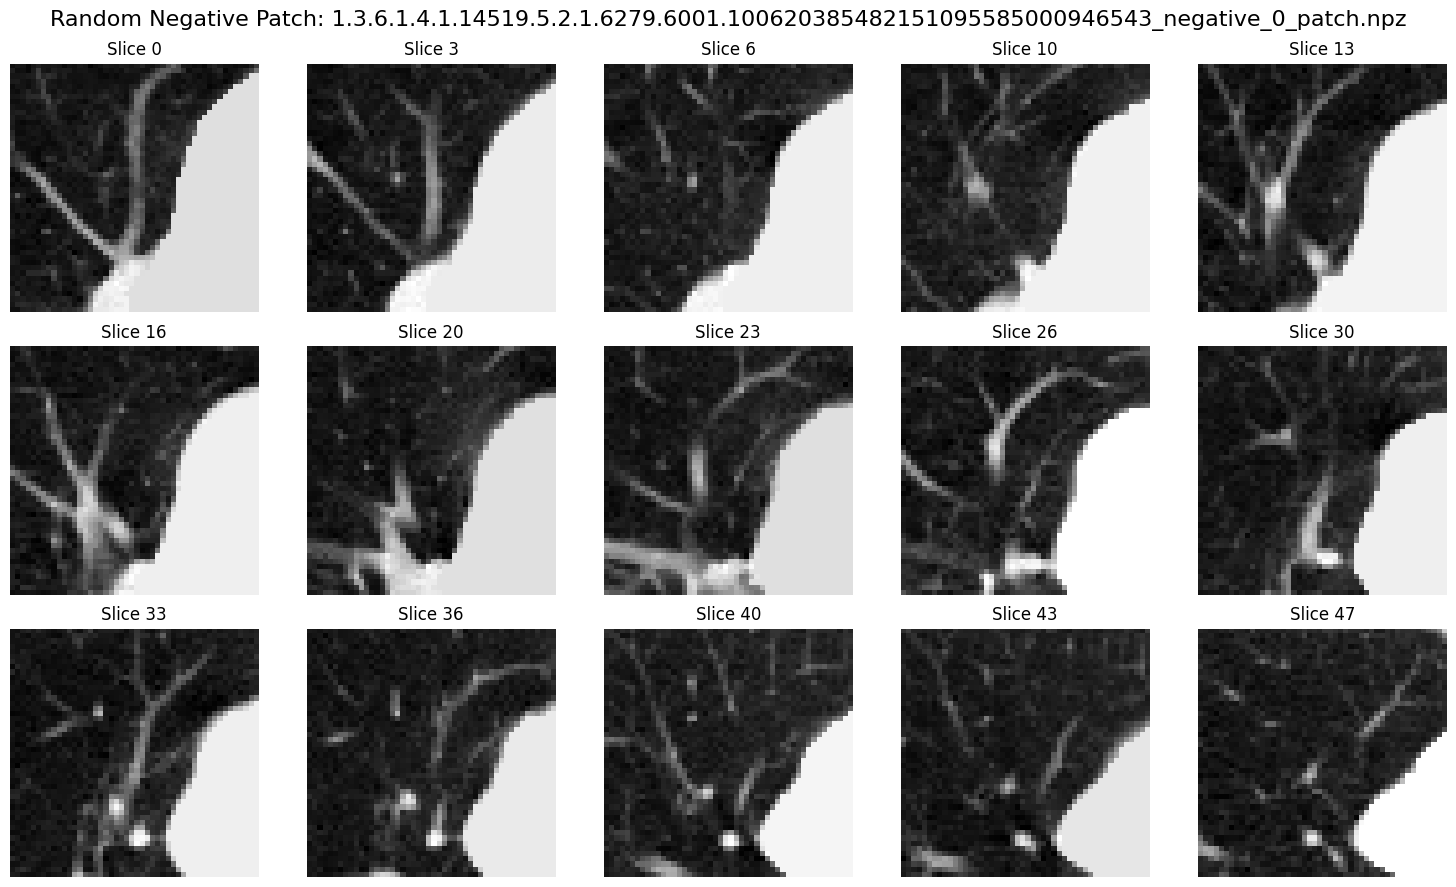

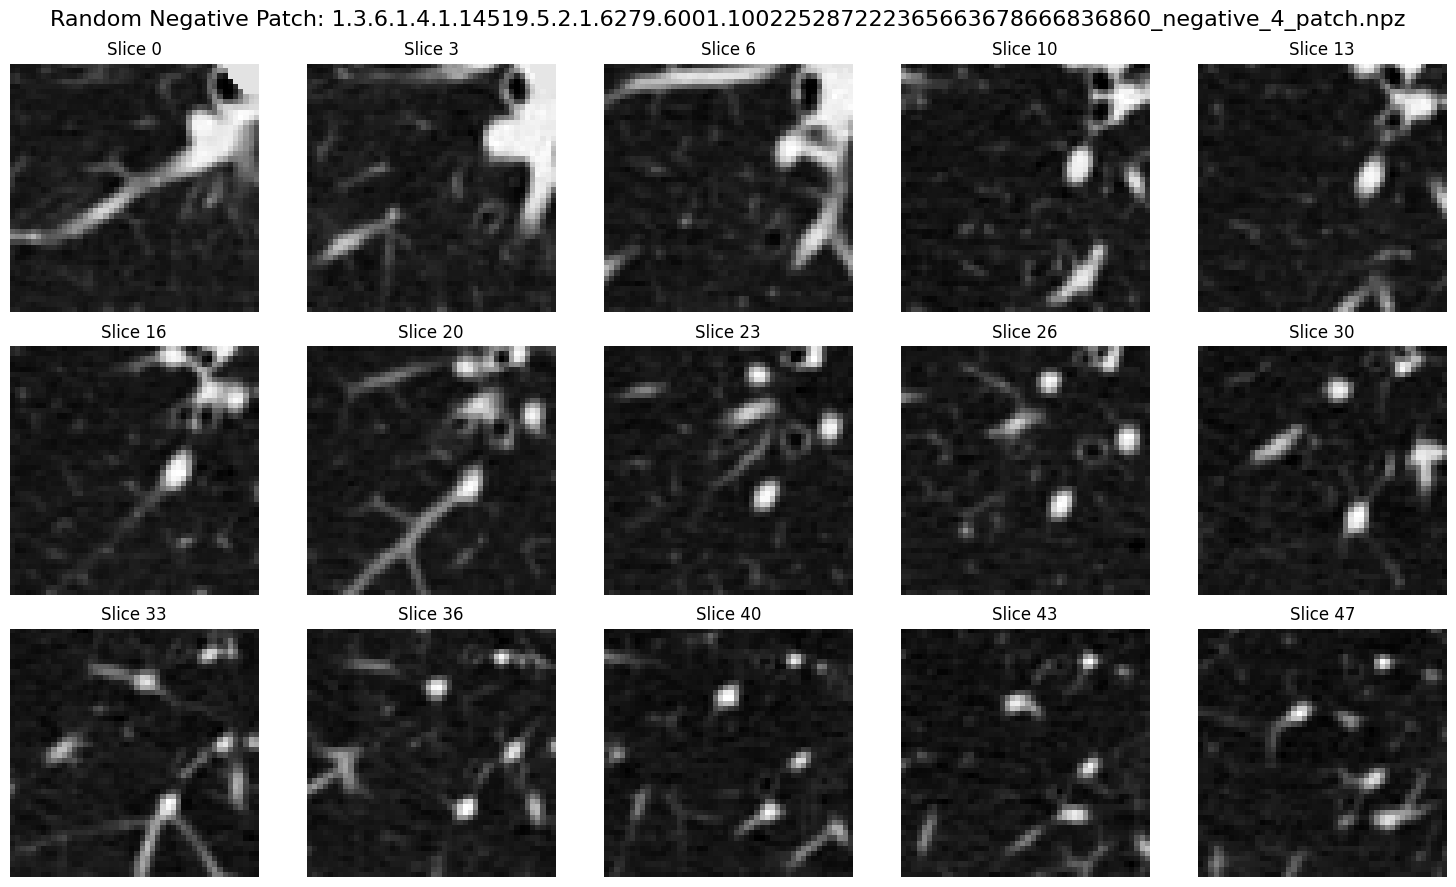

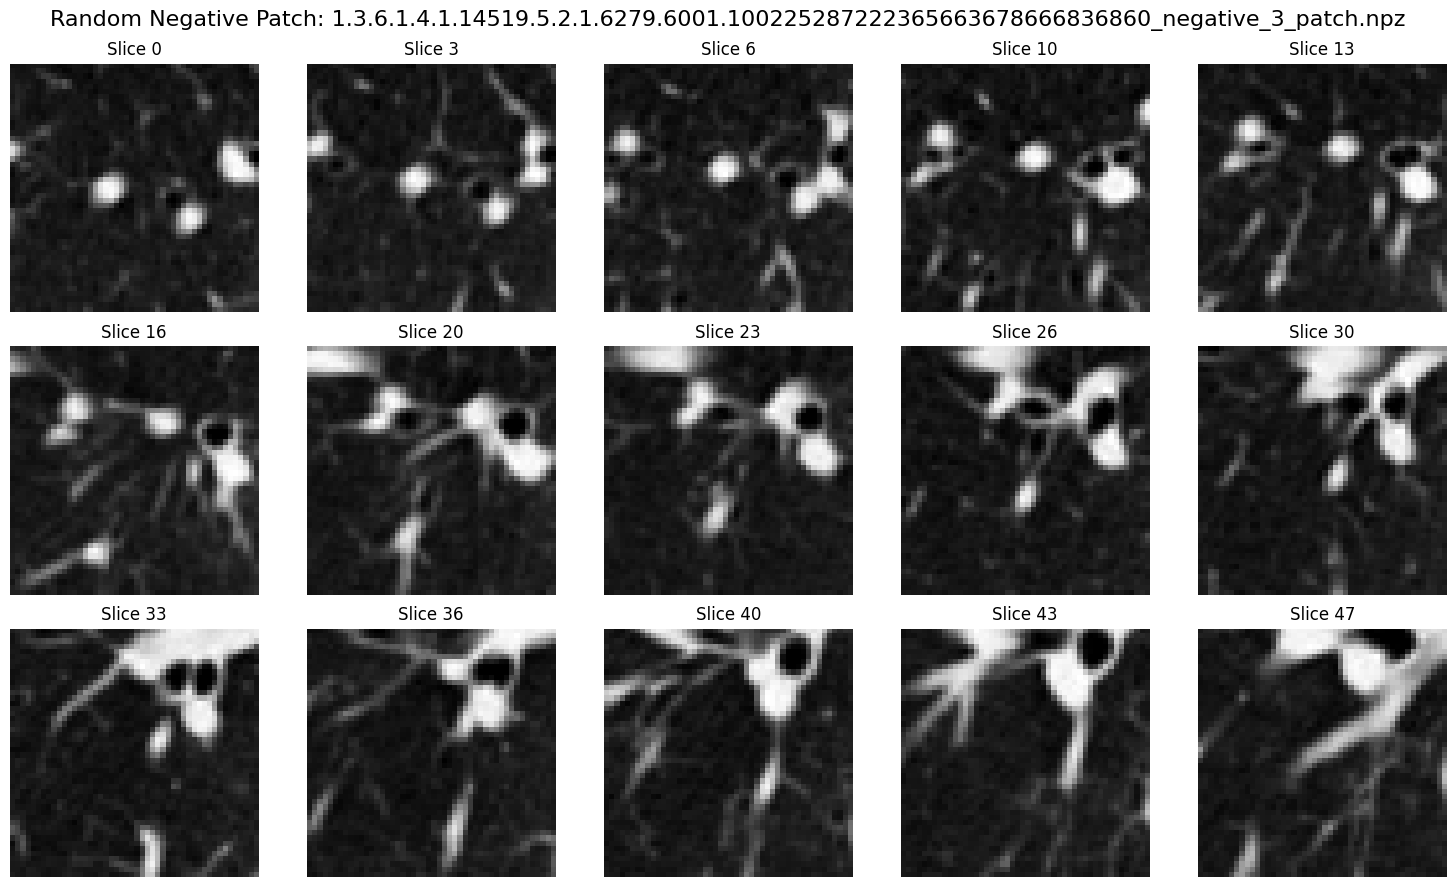

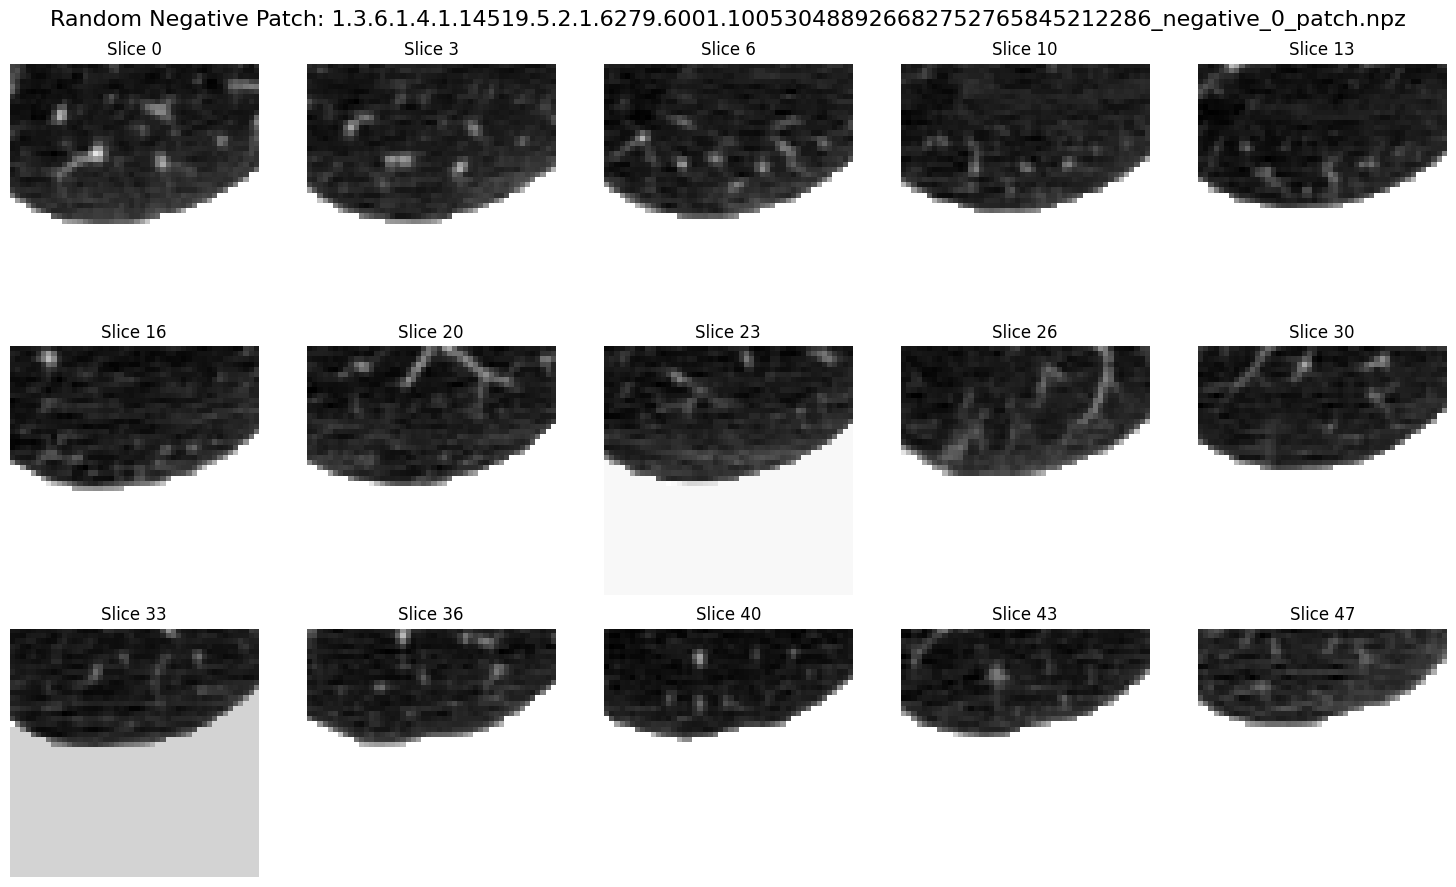

In [85]:
import matplotlib.pyplot as plt

neg_patches = [f for f in os.listdir(negatives_output_folder) if f.endswith('.npz')]
random_patches = random.sample(neg_patches, min(4, len(neg_patches)))

for patch_file in random_patches:
    patch_path = os.path.join(negatives_output_folder, patch_file)
    patch_data = np.load(patch_path)
    patch = patch_data['patch']

    fig, axes = plt.subplots(3, 5, figsize=(15, 9))
    fig.suptitle(f"Random Negative Patch: {patch_file}", fontsize=16)

    slice_idxs = np.linspace(0, patch.shape[0] - 1, 15).astype(int)

    for ax, idx in zip(axes.flat, slice_idxs):
        ax.imshow(patch[idx], cmap='gray')
        ax.set_title(f"Slice {idx}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()


In [87]:
import os

positives_folder = "/media/farah/ADATA SD620/luna 16/final/patches/negatives"
num_negative_patches = len([f for f in os.listdir(positives_folder) if f.endswith('.npz')])

print(f"✅ Total negattive patches: {num_negative_patches}")


✅ Total negattive patches: 2372




###  Data Balancing

We chose a **2:1 ratio** — using **2,372 negative patches** and **1,155 positive patches** — to balance the dataset. This ratio helps in two key ways:

- **Improves generalization**: The model sees more examples of normal lung tissue, which helps reduce false positives.
- **Prevents imbalance**: While nodules are rare, using too many negatives would make the model biased toward predicting "no nodule." A 2:1 ratio keeps the dataset realistic but still learnable.



##  9. Data Augmentation for LUNA16 (with 3D patches)

it’s highly recommended, especially with medical datasets like LUNA16, which are relatively small and imbalanced.
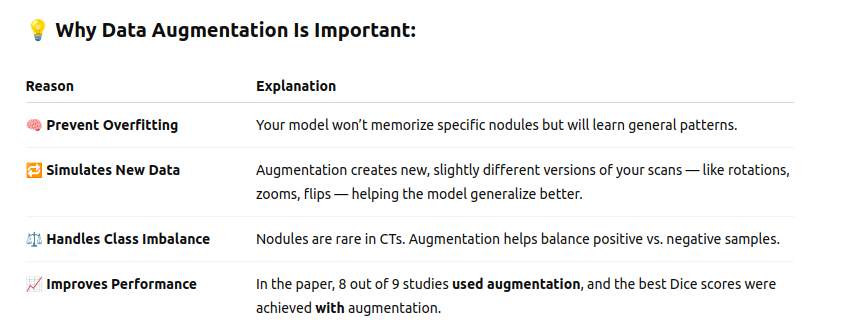


In [89]:
import numpy as np
import scipy.ndimage

class PatchAugmentor:
    def __init__(self, flip_prob=0.5, rotation_range=10, noise_std=0.01, intensity_shift=0.05, zoom_range=(0.9, 1.1)):
        self.flip_prob = flip_prob
        self.rotation_range = rotation_range  # degrees
        self.noise_std = noise_std
        self.intensity_shift = intensity_shift
        self.zoom_range = zoom_range

    def random_flip(self, patch):
        # Flip along axes with some probability
        for axis in range(3):  # z, y, x
            if np.random.rand() < self.flip_prob:
                patch = np.flip(patch, axis=axis)
        return patch

    def random_rotate(self, patch):
        # Random rotation around one random axis
        angle = np.random.uniform(-self.rotation_range, self.rotation_range)
        axis = np.random.choice(3)
        patch = scipy.ndimage.rotate(patch, angle=angle, axes=(axis, (axis+1)%3), reshape=False, order=1, mode='nearest')
        return patch

    def random_noise(self, patch):
        noise = np.random.normal(0, self.noise_std, patch.shape)
        return patch + noise

    def random_intensity_shift(self, patch):
        shift = np.random.uniform(-self.intensity_shift, self.intensity_shift)
        return patch + shift

    def random_zoom(self, patch):
        zoom_factor = np.random.uniform(self.zoom_range[0], self.zoom_range[1])
        patch_zoomed = scipy.ndimage.zoom(patch, zoom_factor, order=1)
        
        # Crop or pad back to original size
        original_shape = patch.shape
        new_shape = patch_zoomed.shape
        
        pad_width = [(0, max(0, original_shape[i] - new_shape[i])) for i in range(3)]
        patch_zoomed = np.pad(patch_zoomed, pad_width, mode='constant')
        patch_zoomed = patch_zoomed[:original_shape[0], :original_shape[1], :original_shape[2]]
        
        return patch_zoomed

    def augment(self, patch):
        patch = self.random_flip(patch)
        patch = self.random_rotate(patch)
        patch = self.random_noise(patch)
        patch = self.random_intensity_shift(patch)
        patch = self.random_zoom(patch)
        return patch


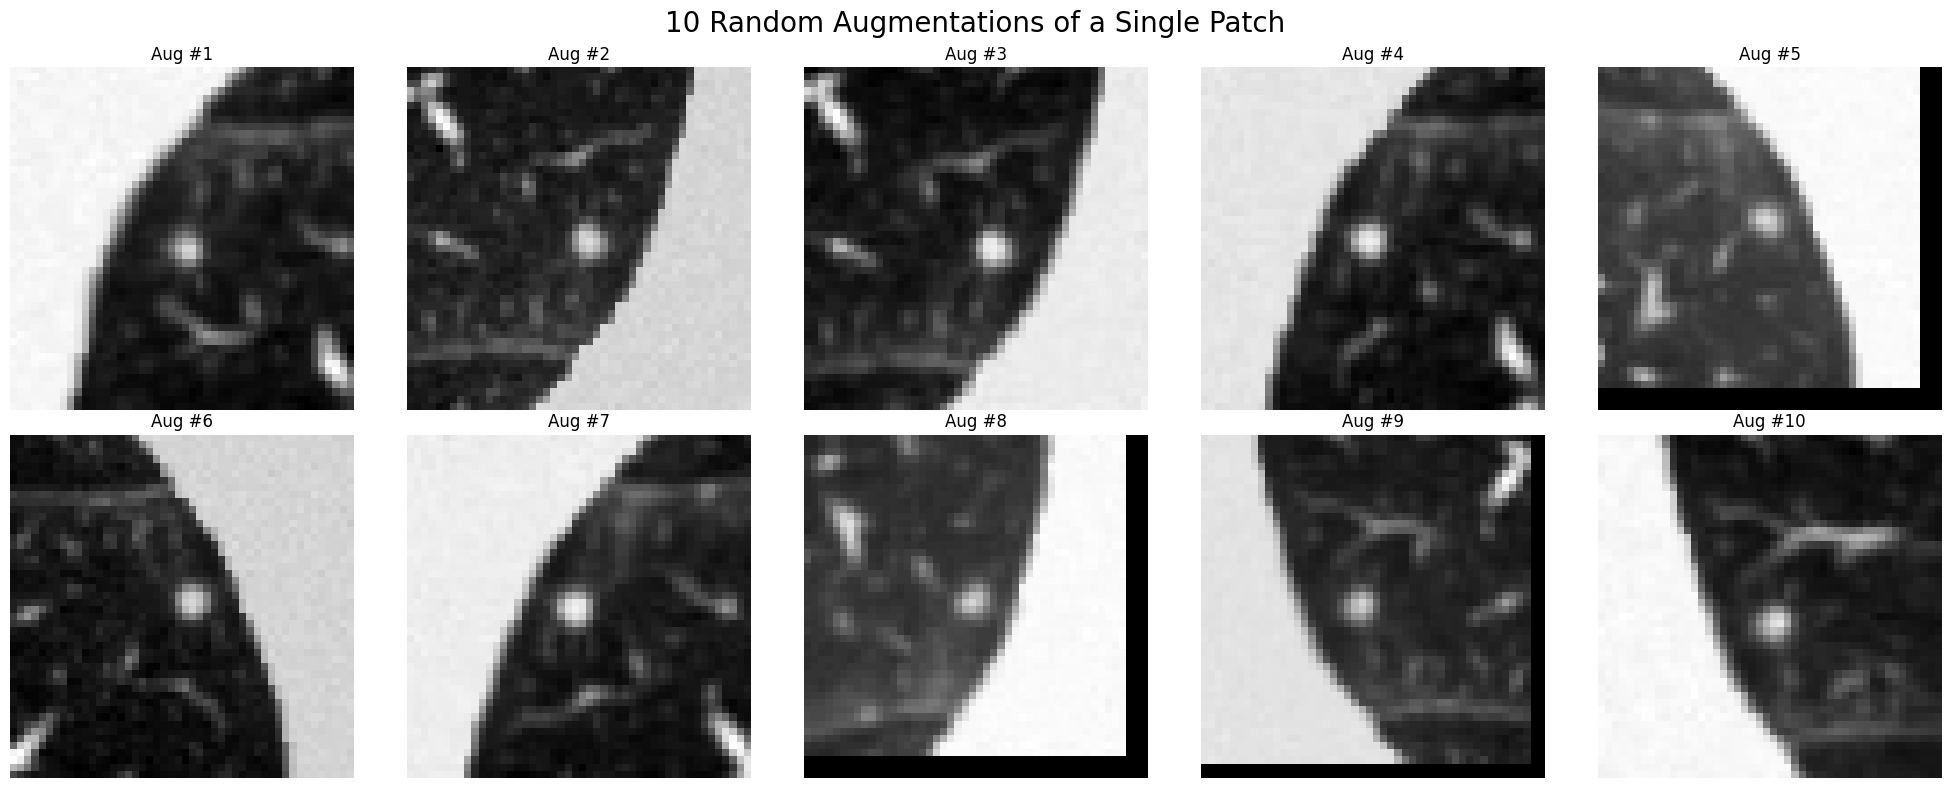

In [93]:
import matplotlib.pyplot as plt
import os
import numpy as np

# 📂 Path to the positives folder
positive_folder = "/media/farah/ADATA SD620/luna 16/final/patches/positives"

# 📋 Randomly pick one .npz file
patch_filename = random.choice([f for f in os.listdir(positive_folder) if f.endswith(".npz")])
patch_path = os.path.join(positive_folder, patch_filename)

# 📂 Load the patch
patch_data = np.load(patch_path)
patch = patch_data['patch']

# 🎨 Create an augmentor
augmentor = PatchAugmentor()

# 📸 Plot 10 different augmentations
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle('10 Random Augmentations of a Single Patch', fontsize=20)

for i in range(10):
    augmented_patch = augmentor.augment(patch)

    center = [s // 2 for s in augmented_patch.shape]

    ax = axes[i // 5, i % 5]
    ax.imshow(augmented_patch[center[0], :, :], cmap='gray')
    ax.set_title(f'Aug #{i+1}')
    ax.axis('off')

plt.tight_layout()
plt.show()


#### we got :
* Different orientations → because of flipping and rotating 

* Different intensities → because of noise and brightness shifting 

* Zoomed in/out slightly → because of zooming 

* Still centered around the nodule → not completely random 

→ This simulates CT variability without destroying the core structure (nodules).

## Summary of Data Acquisition Phase

In this notebook, we completed all the essential preprocessing steps needed to prepare the LUNA16 dataset for deep learning:

- ✅ Clipped and normalized Hounsfield Units (HU) to [0,1] range.
- ✅ Resampled all CT scans to a uniform 1mm³ voxel spacing.
- ✅ Matched CT volumes with nodule annotations from `annotations.csv`.
- ✅ Created accurate 3D binary masks for each annotated nodule.
- ✅ Extracted positive (nodule-centered) and negative (nodule-free) 3D patches.
- ✅ Balanced the dataset with a 2:1 ratio of negative to positive samples.
- ✅ Set the stage for augmentation and loading in the training pipeline.

This completed the **Data Acquisition Phase**, where we transformed raw CT data into a structured, learnable format.

---

## Next: Modeling Phase — Tackling Two DSO Challenges

In the next phase, we’ll begin modeling and focus on solving two main **Data Science Objectives (DSOs)**:

1. 🎯 **LUNA16 Nodule Segmentation**  
   We’ll train a 3D U-Net to segment nodules in CT scans — directly addressing one of the core LUNA16 challenges.

2. 🧭 **Lung Nodule Detection**  
   Building on segmentation, we’ll implement logic to **detect** nodules — locating their positions within the scan volume.

We'll use data augmentation, advanced evaluation metrics, and post-processing techniques to develop accurate and generalizable models.